In [2]:
!pip install minisom openpyxl

  Preparing metadata (setup.py) ... done
  Created wheel for minisom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=1555e5d690c7d6ed7477b3bd3c365d7e195c3c8a0f6a3e704ac4810c84317649
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom


In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.preprocessing import StandardScaler, LabelEncoder
from minisom import MiniSom


# Σύνδεση με Google Drive
drive.mount('/content/drive', force_remount=True)


# Φόρτωση όλων των μετοχών
symbols = ["AAPL", "AIG", "BAC", "GS", "MNST", "MSFT", "NKE", "PFE", "PLUG", "SHOP", "SPCE"]
path = "/content/drive/MyDrive/Βαση Δεδομενων/"

datasets = []

for symbol in symbols:
    df = pd.read_excel(f"{path}{symbol}_Data_Technical_Indicators_Combined.xlsx", parse_dates=[0])
    df.rename(columns={df.columns[0]: "Date"}, inplace=True)
    df.set_index("Date", inplace=True)
    df = df.sort_index()

    # Δημιουργία Next_Close
    df["Next_Close"] = df.iloc[:, 3].shift(-1)

    # Δημιουργία Next_Volume
    df["Next_Volume"] = df.iloc[:, 4].shift(-1)

    # Δημιουργία Trend
    df["Trend"] = df.iloc[:, 3].shift(-30) / df.iloc[:, 3]

    # Δημιουργία Volatility
    df["Volatility"] = df.iloc[:, 8].shift(-1)

    # Προσθήκη συμβόλου μετοχής
    df["Symbol"] = symbol

    datasets.append(df)


# Εύρεση κοινών ημερομηνιών
common_dates = datasets[0].index

for df in datasets[1:]:
    common_dates = common_dates.intersection(df.index)


# Φιλτράρισμα στις κοινές ημερομηνίες
for i in range(len(datasets)):
    datasets[i] = datasets[i].loc[common_dates]


# Ενοποίηση όλων των datasets
dataset = pd.concat(datasets, axis=0)

dataset = dataset.replace([np.inf, -np.inf], np.nan)
dataset = dataset.dropna()


# Κωδικοποίηση Symbol
le = LabelEncoder()
dataset["Symbol_enc"] = le.fit_transform(dataset["Symbol"])

num_symbols = dataset["Symbol_enc"].nunique()

print("Συνολικό μέγεθος dataset:", dataset.shape)
print("Αριθμός μετοχών:", num_symbols)
print("Μετοχές:", le.classes_)
print("Στήλες dataset:", dataset.columns.tolist())

Mounted at /content/drive
Συνολικό μέγεθος dataset: (16280, 29)
Αριθμός μετοχών: 11
Μετοχές: ['AAPL' 'AIG' 'BAC' 'GS' 'MNST' 'MSFT' 'NKE' 'PFE' 'PLUG' 'SHOP' 'SPCE']
Στήλες dataset: ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'SMA', 'EMA', 'ATR', 'Real Upper Band', 'Real Middle Band', 'Real Lower Band', 'SlowK', 'SlowD', 'ADX', 'S&P 500', 'VIX', 'Gold', 'Crude Oil', '10Y Treasury Yield', 'Rice Prices', 'FED Funds Rate', "Stock's Name", 'Next_Close', 'Next_Volume', 'Trend', 'Volatility', 'Symbol', 'Symbol_enc']


In [12]:
features = ["Open","High","Low","Close","Volume","RSI","SMA","EMA","ATR","Real Upper Band","Real Middle Band","Real Lower Band","SlowK","SlowD","ADX","S&P 500","VIX","Gold","Crude Oil","10Y Treasury Yield","Rice Prices","FED Funds Rate"]

# Targets
targets = ["Next_Close", "Next_Volume", "Trend", "Volatility"]

print("Αριθμός χαρακτηριστικών:", len(features))
print("Targets:", targets)

Αριθμός χαρακτηριστικών: 22
Targets: ['Next_Close', 'Next_Volume', 'Trend', 'Volatility']


In [13]:
# Φάκελος αποθήκευσης αποτελεσμάτων
output_path = "/content/drive/MyDrive/Βαση Δεδομενων/SOM_RESULTS/"

os.makedirs(output_path, exist_ok=True)

print("Τα αποτελέσματα θα αποθηκευτούν στο:", output_path)

Τα αποτελέσματα θα αποθηκευτούν στο: /content/drive/MyDrive/Βαση Δεδομενων/SOM_RESULTS/


In [14]:
def run_som(dataset, features, target, som_x=15, som_y=15, iterations=10000, random_seed=42):

    print("\n" + "=" * 70)
    print("SOM ΓΙΑ TARGET:", target)
    print("=" * 70)

    som_columns = features + [target]
    som_df = dataset[som_columns].copy()
    som_df = som_df.replace([np.inf, -np.inf], np.nan).dropna()

    print("Αριθμός παρατηρήσεων:", len(som_df))

    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(som_df)

    som = MiniSom(
        x=som_x, y=som_y, input_len=scaled_data.shape[1],
        sigma=1.5, learning_rate=0.5,
        neighborhood_function="gaussian", random_seed=random_seed
    )

    som.random_weights_init(scaled_data)

    print("\nΕκπαίδευση SOM...")
    som.train_random(data=scaled_data, num_iteration=iterations, verbose=True)
    print("Η εκπαίδευση ολοκληρώθηκε.")

    u_matrix = som.distance_map().T

    plt.figure(figsize=(10, 8))
    im = plt.imshow(u_matrix, origin="lower", cmap="Blues")
    plt.colorbar(im, label="Distance")
    plt.title(f"SOM U-Matrix - {target}")
    plt.xlabel("SOM X")
    plt.ylabel("SOM Y")

    norm = plt.Normalize(vmin=u_matrix.min(), vmax=u_matrix.max())

    for y in range(u_matrix.shape[0]):
        for x in range(u_matrix.shape[1]):
            value = u_matrix[y, x]
            r, g, b, _ = im.cmap(norm(value))
            brightness = 0.299 * r + 0.587 * g + 0.114 * b
            text_color = "black" if brightness > 0.55 else "white"

            plt.text(
                x, y, f"{value:.2f}",
                ha="center", va="center",
                fontsize=7, color=text_color, fontweight="bold"
            )

    plt.tight_layout()

    u_matrix_file = f"{output_path}{target}_U_Matrix.png"
    plt.savefig(u_matrix_file, dpi=300, bbox_inches="tight")
    plt.show()

    weights = som.get_weights()
    column_names = features + [target]
    n_features = len(column_names)

    print("\nΔιαστάσεις SOM weights:", weights.shape)
    print("Αριθμός Component Maps:", n_features)

    cols = 4
    rows = int(np.ceil(n_features / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(24, rows * 5))
    axes = np.array(axes).flatten()

    for i, feature in enumerate(column_names):

        component_map = weights[:, :, i]
        displayed_map = component_map.T

        im = axes[i].imshow(displayed_map, origin="lower", cmap="Blues")
        axes[i].set_title(feature, fontsize=11)
        axes[i].set_xlabel("SOM X")
        axes[i].set_ylabel("SOM Y")

        norm = plt.Normalize(vmin=displayed_map.min(), vmax=displayed_map.max())

        for y in range(displayed_map.shape[0]):
            for x in range(displayed_map.shape[1]):

                value = displayed_map[y, x]
                r, g, b, _ = im.cmap(norm(value))
                brightness = 0.299 * r + 0.587 * g + 0.114 * b
                text_color = "black" if brightness > 0.55 else "white"

                axes[i].text(
                    x, y, f"{value:.2f}",
                    ha="center", va="center",
                    fontsize=4, color=text_color, fontweight="bold"
                )

        plt.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

    for i in range(n_features, len(axes)):
        axes[i].axis("off")

    plt.suptitle(f"SOM Component Maps - {target}", fontsize=18, y=1.00)
    plt.tight_layout()

    component_file = f"{output_path}{target}_Component_Maps_With_Values.png"
    plt.savefig(component_file, dpi=300, bbox_inches="tight")
    plt.show()

    target_index = column_names.index(target)
    target_map = weights[:, :, target_index]
    displayed_target_map = target_map.T

    plt.figure(figsize=(9, 8))

    im = plt.imshow(displayed_target_map, origin="lower", cmap="Blues")
    plt.colorbar(im, label=target)
    plt.title(f"SOM Component Map - {target}")
    plt.xlabel("SOM X")
    plt.ylabel("SOM Y")

    norm = plt.Normalize(
        vmin=displayed_target_map.min(),
        vmax=displayed_target_map.max()
    )

    for y in range(displayed_target_map.shape[0]):
        for x in range(displayed_target_map.shape[1]):

            value = displayed_target_map[y, x]
            r, g, b, _ = im.cmap(norm(value))
            brightness = 0.299 * r + 0.587 * g + 0.114 * b
            text_color = "black" if brightness > 0.55 else "white"

            plt.text(
                x, y, f"{value:.2f}",
                ha="center", va="center",
                fontsize=7, color=text_color, fontweight="bold"
            )

    plt.tight_layout()

    target_file = f"{output_path}{target}_Target_Map_With_Values.png"
    plt.savefig(target_file, dpi=300, bbox_inches="tight")
    plt.show()

    target_flat = target_map.flatten()
    correlations = []

    for i, feature in enumerate(features):

        feature_map = weights[:, :, i]
        feature_flat = feature_map.flatten()
        correlation = np.corrcoef(target_flat, feature_flat)[0, 1]

        correlations.append({
            "Feature": feature,
            "Correlation": correlation,
            "Absolute_Correlation": abs(correlation)
        })

    correlation_df = pd.DataFrame(correlations)

    correlation_df = correlation_df.sort_values(
        by="Absolute_Correlation", ascending=False
    ).reset_index(drop=True)

    print("\n" + "=" * 70)
    print("ΧΑΡΑΚΤΗΡΙΣΤΙΚΑ ΜΕ ΤΗ ΜΕΓΑΛΥΤΕΡΗ ΣΥΣΧΕΤΙΣΗ ΜΕ", target)
    print("=" * 70)

    print(correlation_df[["Feature", "Correlation", "Absolute_Correlation"]])

    excel_file = f"{output_path}{target}_SOM_Correlations.xlsx"
    correlation_df.to_excel(excel_file, index=False)

    plot_df = correlation_df.sort_values("Correlation")

    plt.figure(figsize=(11, 9))
    plt.barh(plot_df["Feature"], plot_df["Correlation"])
    plt.axvline(x=0, linewidth=1, color="black")
    plt.xlabel("Correlation μεταξύ SOM Component Maps")
    plt.ylabel("Χαρακτηριστικό")
    plt.title(f"SOM - Σχέση Χαρακτηριστικών με {target}")
    plt.tight_layout()

    correlation_file = f"{output_path}{target}_Correlations.png"
    plt.savefig(correlation_file, dpi=300, bbox_inches="tight")
    plt.show()

    top_10 = correlation_df.head(10).copy()

    print("\n" + "=" * 70)
    print("TOP 10 ΧΑΡΑΚΤΗΡΙΣΤΙΚΑ ΓΙΑ", target)
    print("=" * 70)

    print(top_10[["Feature", "Correlation", "Absolute_Correlation"]])

    top_plot = top_10.sort_values("Correlation")

    plt.figure(figsize=(10, 6))
    plt.barh(top_plot["Feature"], top_plot["Correlation"])
    plt.axvline(x=0, linewidth=1, color="black")
    plt.xlabel("SOM Correlation")
    plt.title(f"Top 10 SOM Χαρακτηριστικά - {target}")
    plt.tight_layout()

    top_file = f"{output_path}{target}_Top10.png"
    plt.savefig(top_file, dpi=300, bbox_inches="tight")
    plt.show()

    component_vectors = weights.reshape(-1, weights.shape[2])
    som_corr = np.corrcoef(component_vectors, rowvar=False)

    som_corr_df = pd.DataFrame(
        som_corr,
        index=column_names,
        columns=column_names
    )

    print("\n" + "=" * 70)
    print("ΠΛΗΡΗΣ ΠΙΝΑΚΑΣ ΣΥΣΧΕΤΙΣΕΩΝ SOM COMPONENT MAPS")
    print("=" * 70)
    print(som_corr_df.round(2))

    full_excel_file = f"{output_path}{target}_Component_Correlation_Matrix.xlsx"
    som_corr_df.to_excel(full_excel_file)

    import seaborn as sns

    plt.figure(figsize=(22, 19))

    ax = sns.heatmap(
        som_corr_df,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
        linecolor="white",
        annot_kws={"size": 7, "weight": "bold"},
        cbar_kws={"label": "Correlation"}
    )

    for text in ax.texts:

        value = float(text.get_text())

        if abs(value) >= 0.55:
            text.set_color("white")
        else:
            text.set_color("black")

    plt.title(f"SOM Component Maps Correlation Matrix - {target}", fontsize=16)
    plt.xticks(rotation=90, fontsize=9)
    plt.yticks(rotation=0, fontsize=9)
    plt.tight_layout()

    full_matrix_file = f"{output_path}{target}_Component_Correlation_Matrix.png"
    plt.savefig(full_matrix_file, dpi=300, bbox_inches="tight")
    plt.show()

    high_correlations = []

    for i in range(len(column_names)):
        for j in range(i + 1, len(column_names)):

            corr_value = som_corr_df.iloc[i, j]

            high_correlations.append({
                "Variable_1": column_names[i],
                "Variable_2": column_names[j],
                "Correlation": corr_value,
                "Absolute_Correlation": abs(corr_value)
            })

    high_corr_df = pd.DataFrame(high_correlations)

    high_corr_df = high_corr_df.sort_values(
        by="Absolute_Correlation", ascending=False
    ).reset_index(drop=True)

    print("\n" + "=" * 70)
    print("ΜΕΓΑΛΥΤΕΡΕΣ ΕΤΕΡΟΣΥΣΧΕΤΙΣΕΙΣ ΜΕΤΑΞΥ ΤΩΝ COMPONENT MAPS")
    print("=" * 70)

    print(
        high_corr_df.head(30)[
            ["Variable_1", "Variable_2", "Correlation"]
        ]
    )

    high_corr_excel = f"{output_path}{target}_Component_Correlation_Pairs.xlsx"
    high_corr_df.to_excel(high_corr_excel, index=False)

    print("\n" + "=" * 70)
    print("ΟΛΑ ΤΑ ΑΠΟΤΕΛΕΣΜΑΤΑ ΑΠΟΘΗΚΕΥΤΗΚΑΝ")
    print("=" * 70)

    print("U-Matrix:", u_matrix_file)
    print("Component Maps:", component_file)
    print("Target Map:", target_file)
    print("Συσχετίσεις με Target:", excel_file)
    print("Πλήρης πίνακας συσχετίσεων:", full_excel_file)
    print("Heatmap πίνακα συσχετίσεων:", full_matrix_file)
    print("Ζεύγη ετεροσυσχετίσεων:", high_corr_excel)

    return som, correlation_df


SOM ΓΙΑ TARGET: Next_Close
Αριθμός παρατηρήσεων: 16280

Εκπαίδευση SOM...
 [ 10000 / 10000 ] 100% - 0:00:00 left 
 quantization error: 1.6471539141845952
Η εκπαίδευση ολοκληρώθηκε.


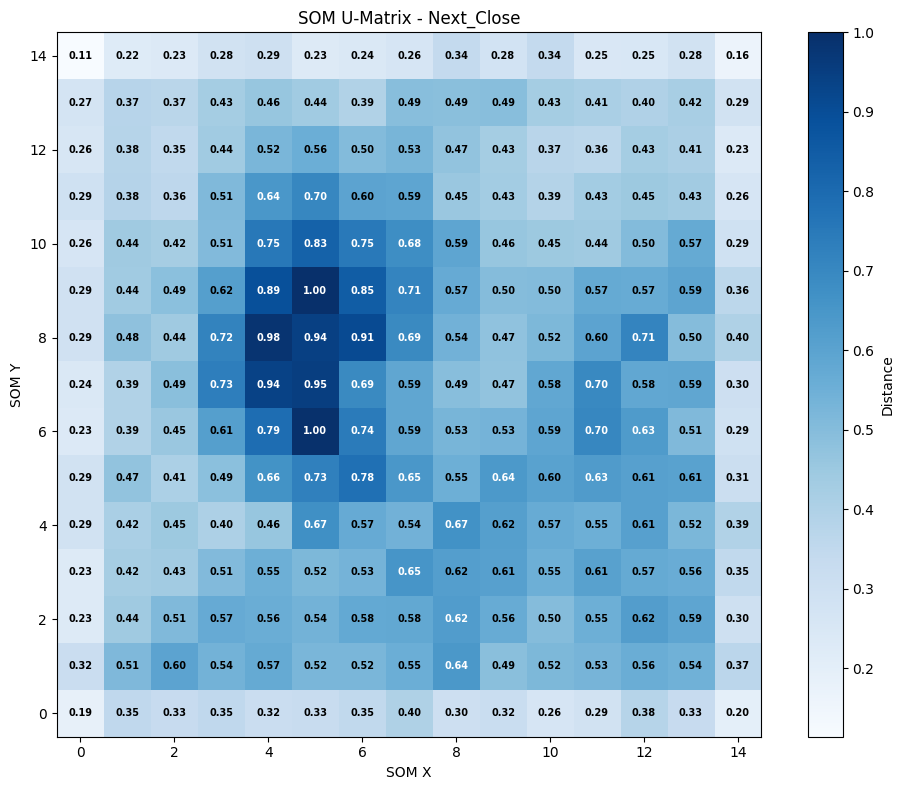


Διαστάσεις SOM weights: (15, 15, 23)
Αριθμός Component Maps: 23


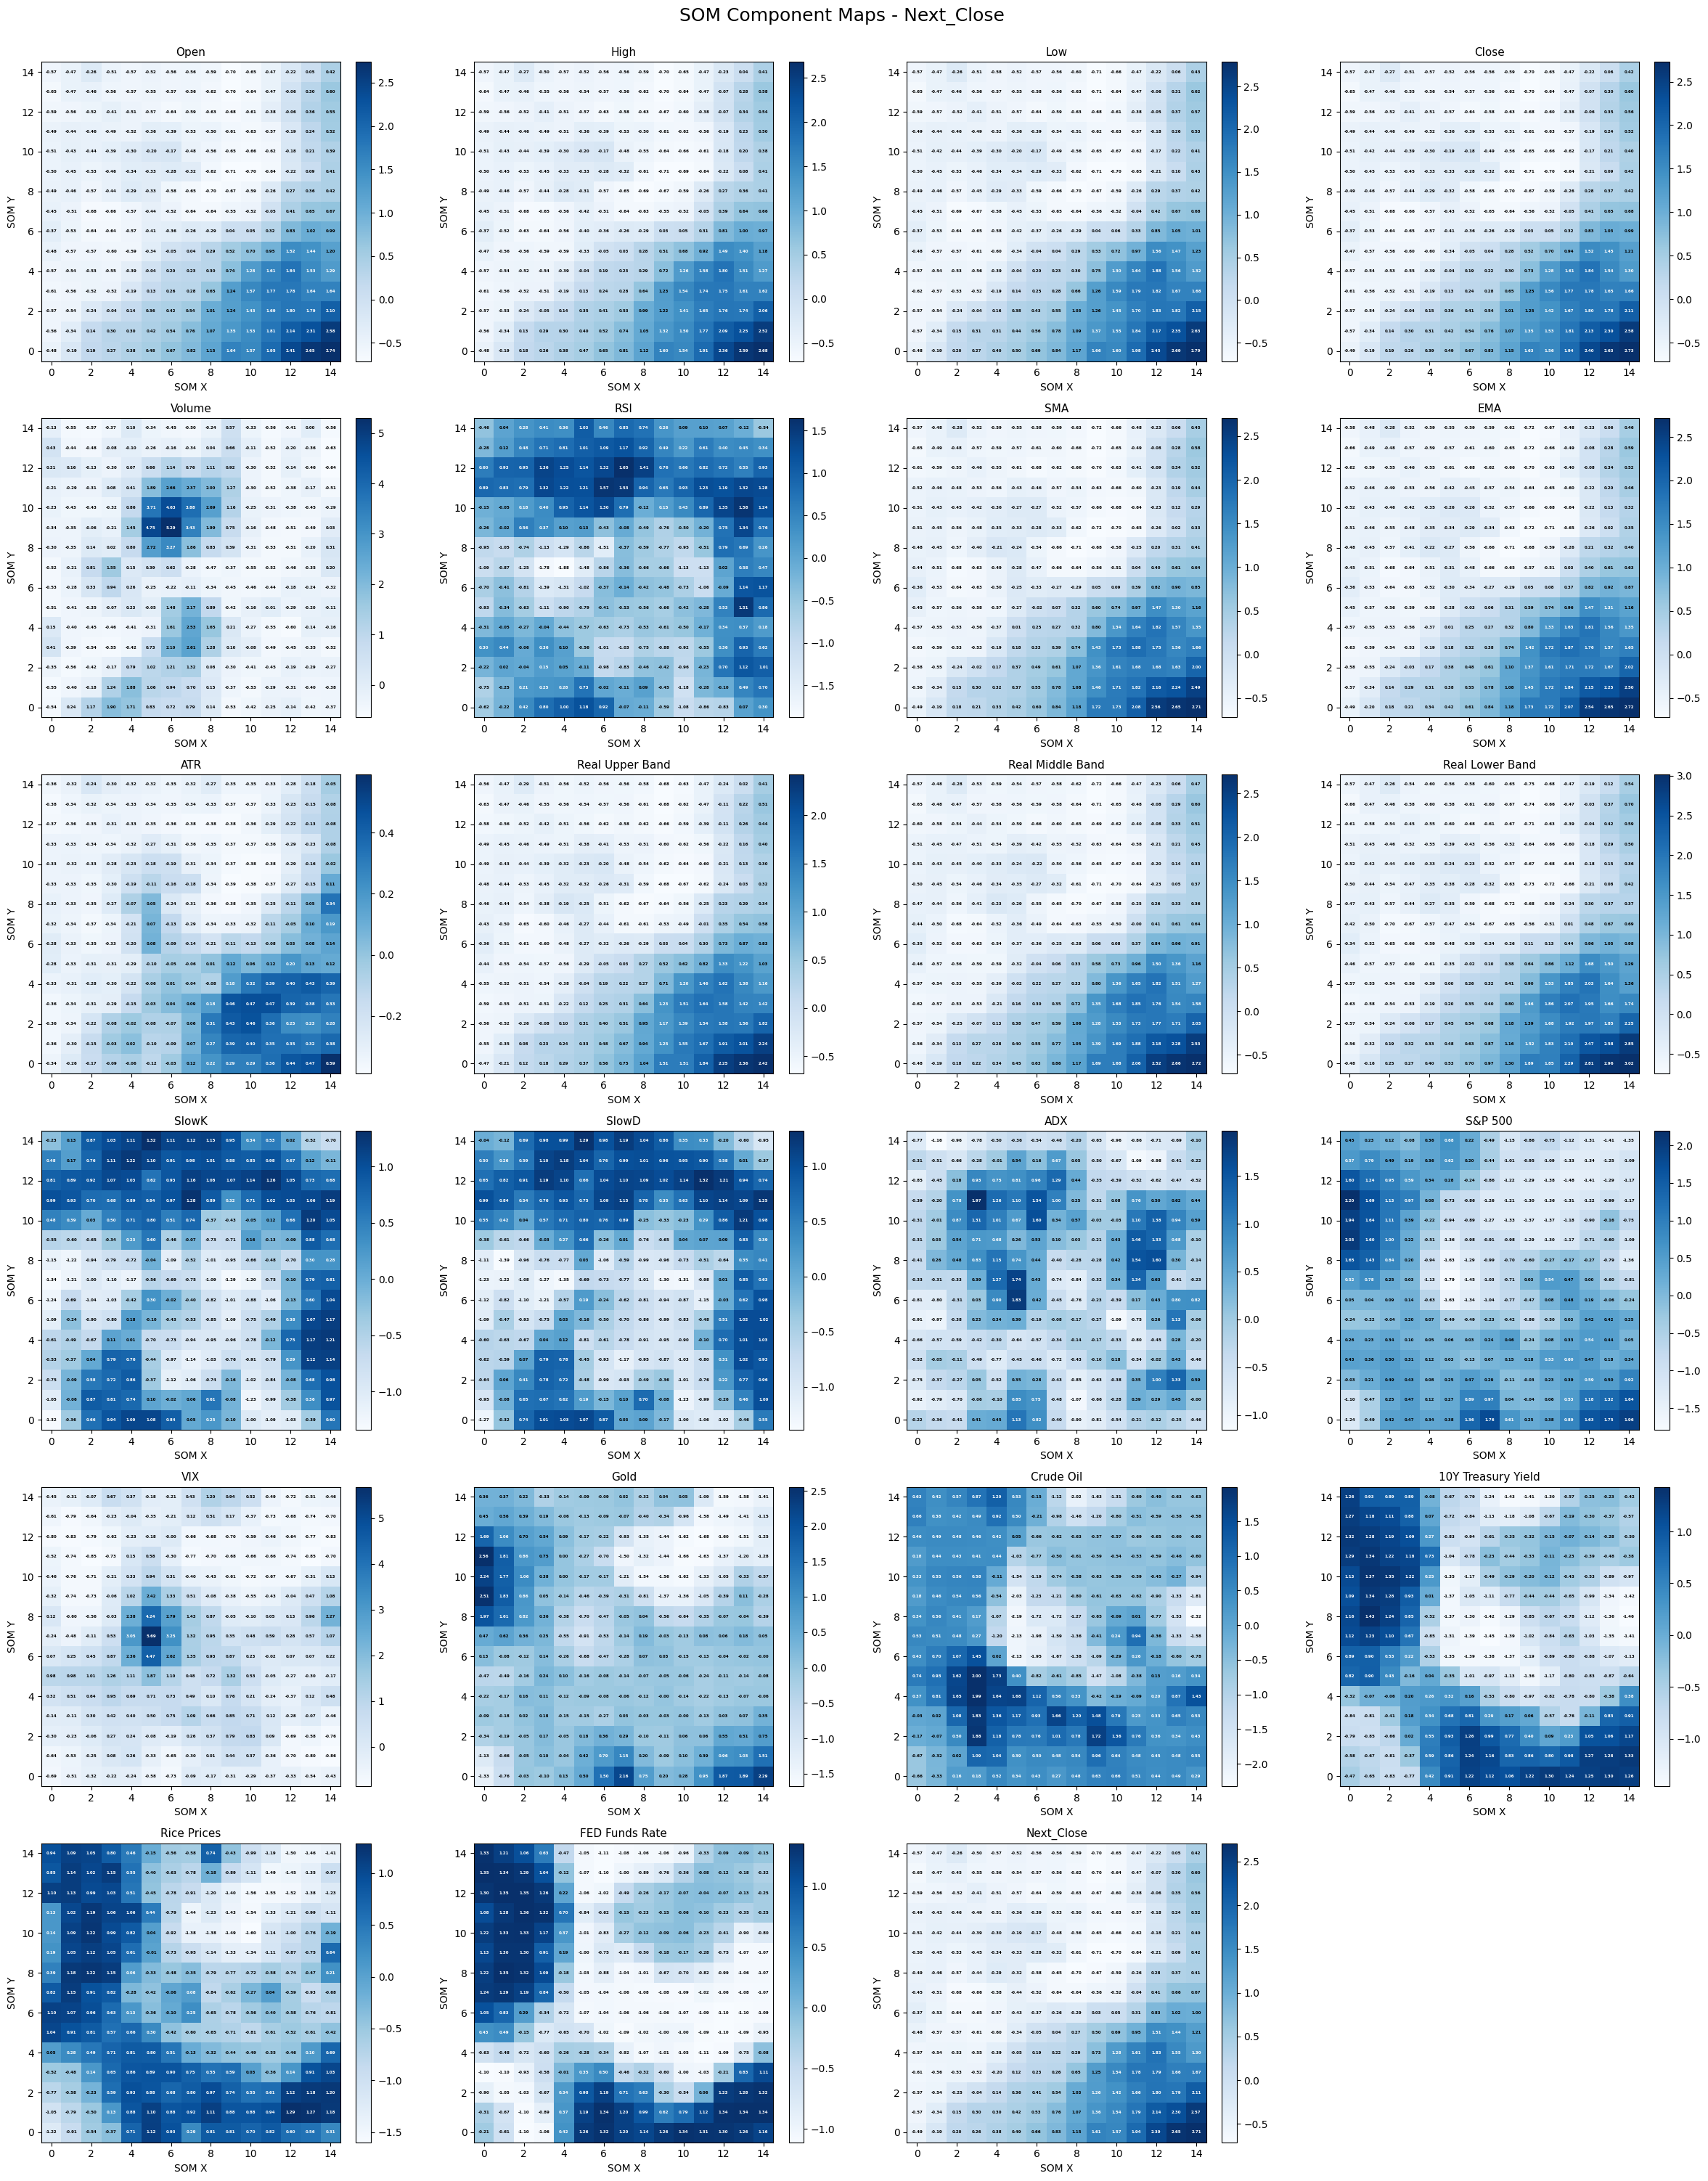

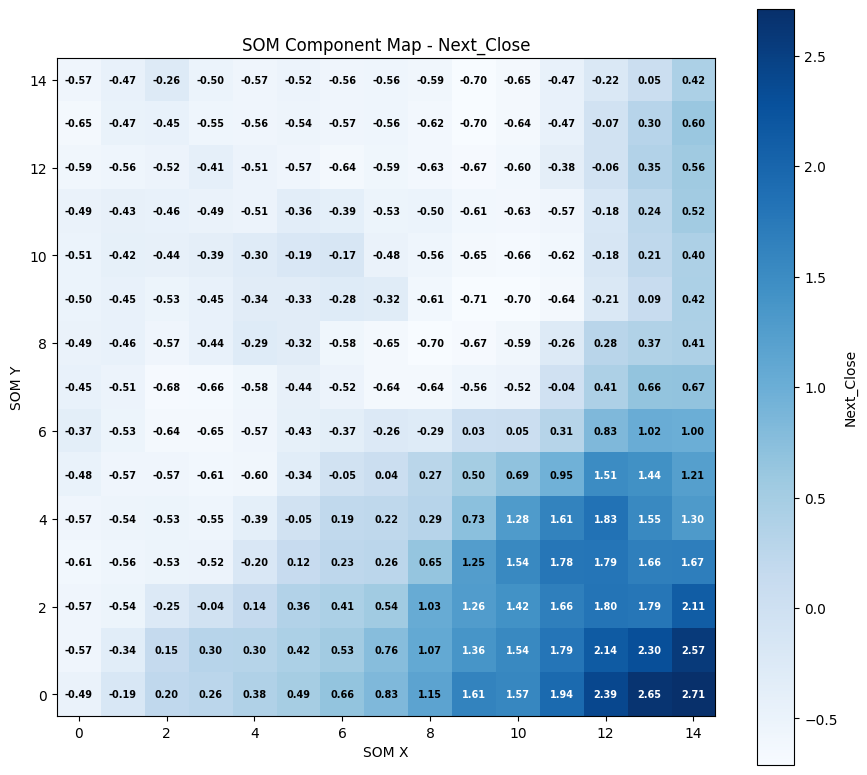


ΧΑΡΑΚΤΗΡΙΣΤΙΚΑ ΜΕ ΤΗ ΜΕΓΑΛΥΤΕΡΗ ΣΥΣΧΕΤΙΣΗ ΜΕ Next_Close
               Feature  Correlation  Absolute_Correlation
0                Close     0.999980              0.999980
1                  Low     0.999968              0.999968
2                 High     0.999962              0.999962
3                 Open     0.999960              0.999960
4     Real Middle Band     0.998890              0.998890
5      Real Lower Band     0.998635              0.998635
6      Real Upper Band     0.998621              0.998621
7                  EMA     0.998120              0.998120
8                  SMA     0.997673              0.997673
9                  ATR     0.939528              0.939528
10             S&P 500     0.343264              0.343264
11                Gold     0.288649              0.288649
12         Rice Prices     0.225155              0.225155
13           Crude Oil     0.216479              0.216479
14  10Y Treasury Yield     0.214218              0.214218
15      FED Fun

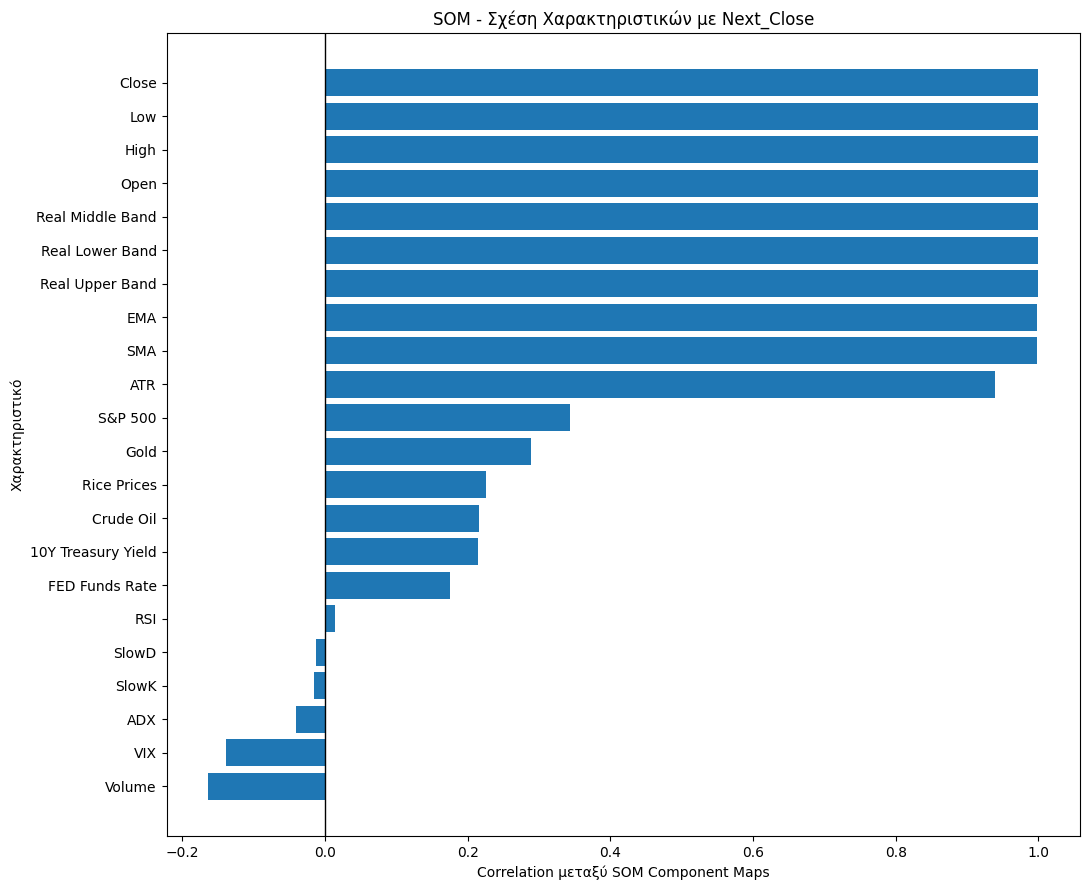


TOP 10 ΧΑΡΑΚΤΗΡΙΣΤΙΚΑ ΓΙΑ Next_Close
            Feature  Correlation  Absolute_Correlation
0             Close     0.999980              0.999980
1               Low     0.999968              0.999968
2              High     0.999962              0.999962
3              Open     0.999960              0.999960
4  Real Middle Band     0.998890              0.998890
5   Real Lower Band     0.998635              0.998635
6   Real Upper Band     0.998621              0.998621
7               EMA     0.998120              0.998120
8               SMA     0.997673              0.997673
9               ATR     0.939528              0.939528


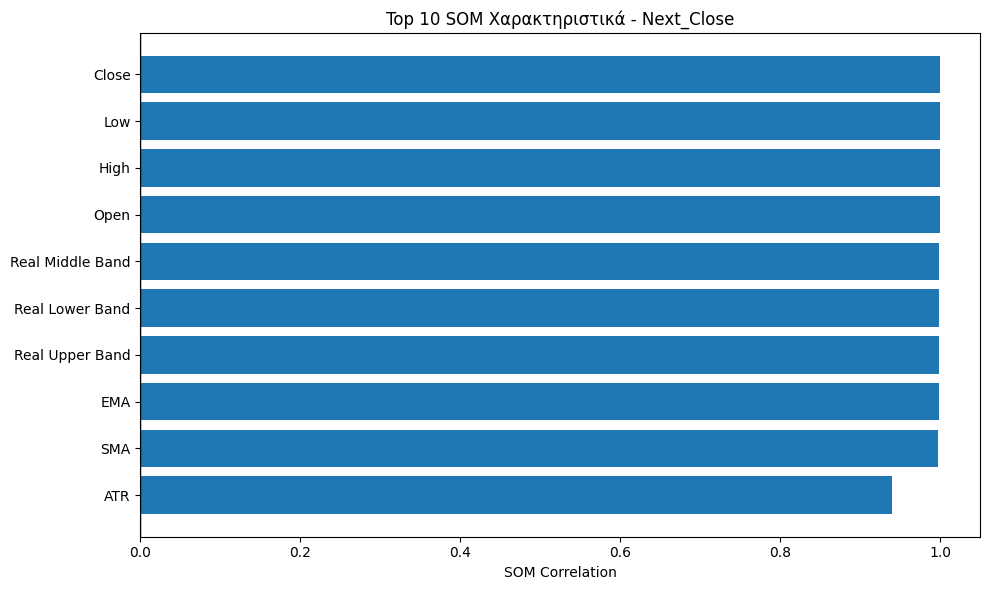


ΠΛΗΡΗΣ ΠΙΝΑΚΑΣ ΣΥΣΧΕΤΙΣΕΩΝ SOM COMPONENT MAPS
                    Open  High   Low  Close  Volume   RSI   SMA   EMA   ATR  \
Open                1.00  1.00  1.00   1.00   -0.16  0.01  1.00  1.00  0.94   
High                1.00  1.00  1.00   1.00   -0.16  0.01  1.00  1.00  0.94   
Low                 1.00  1.00  1.00   1.00   -0.16  0.01  1.00  1.00  0.94   
Close               1.00  1.00  1.00   1.00   -0.16  0.01  1.00  1.00  0.94   
Volume             -0.16 -0.16 -0.16  -0.16    1.00 -0.01 -0.16 -0.16 -0.08   
RSI                 0.01  0.01  0.01   0.01   -0.01  1.00 -0.04 -0.03 -0.14   
SMA                 1.00  1.00  1.00   1.00   -0.16 -0.04  1.00  1.00  0.95   
EMA                 1.00  1.00  1.00   1.00   -0.16 -0.03  1.00  1.00  0.95   
ATR                 0.94  0.94  0.94   0.94   -0.08 -0.14  0.95  0.95  1.00   
Real Upper Band     1.00  1.00  1.00   1.00   -0.16 -0.02  1.00  1.00  0.95   
Real Middle Band    1.00  1.00  1.00   1.00   -0.16 -0.02  1.00  1.00  0.94   
Real 

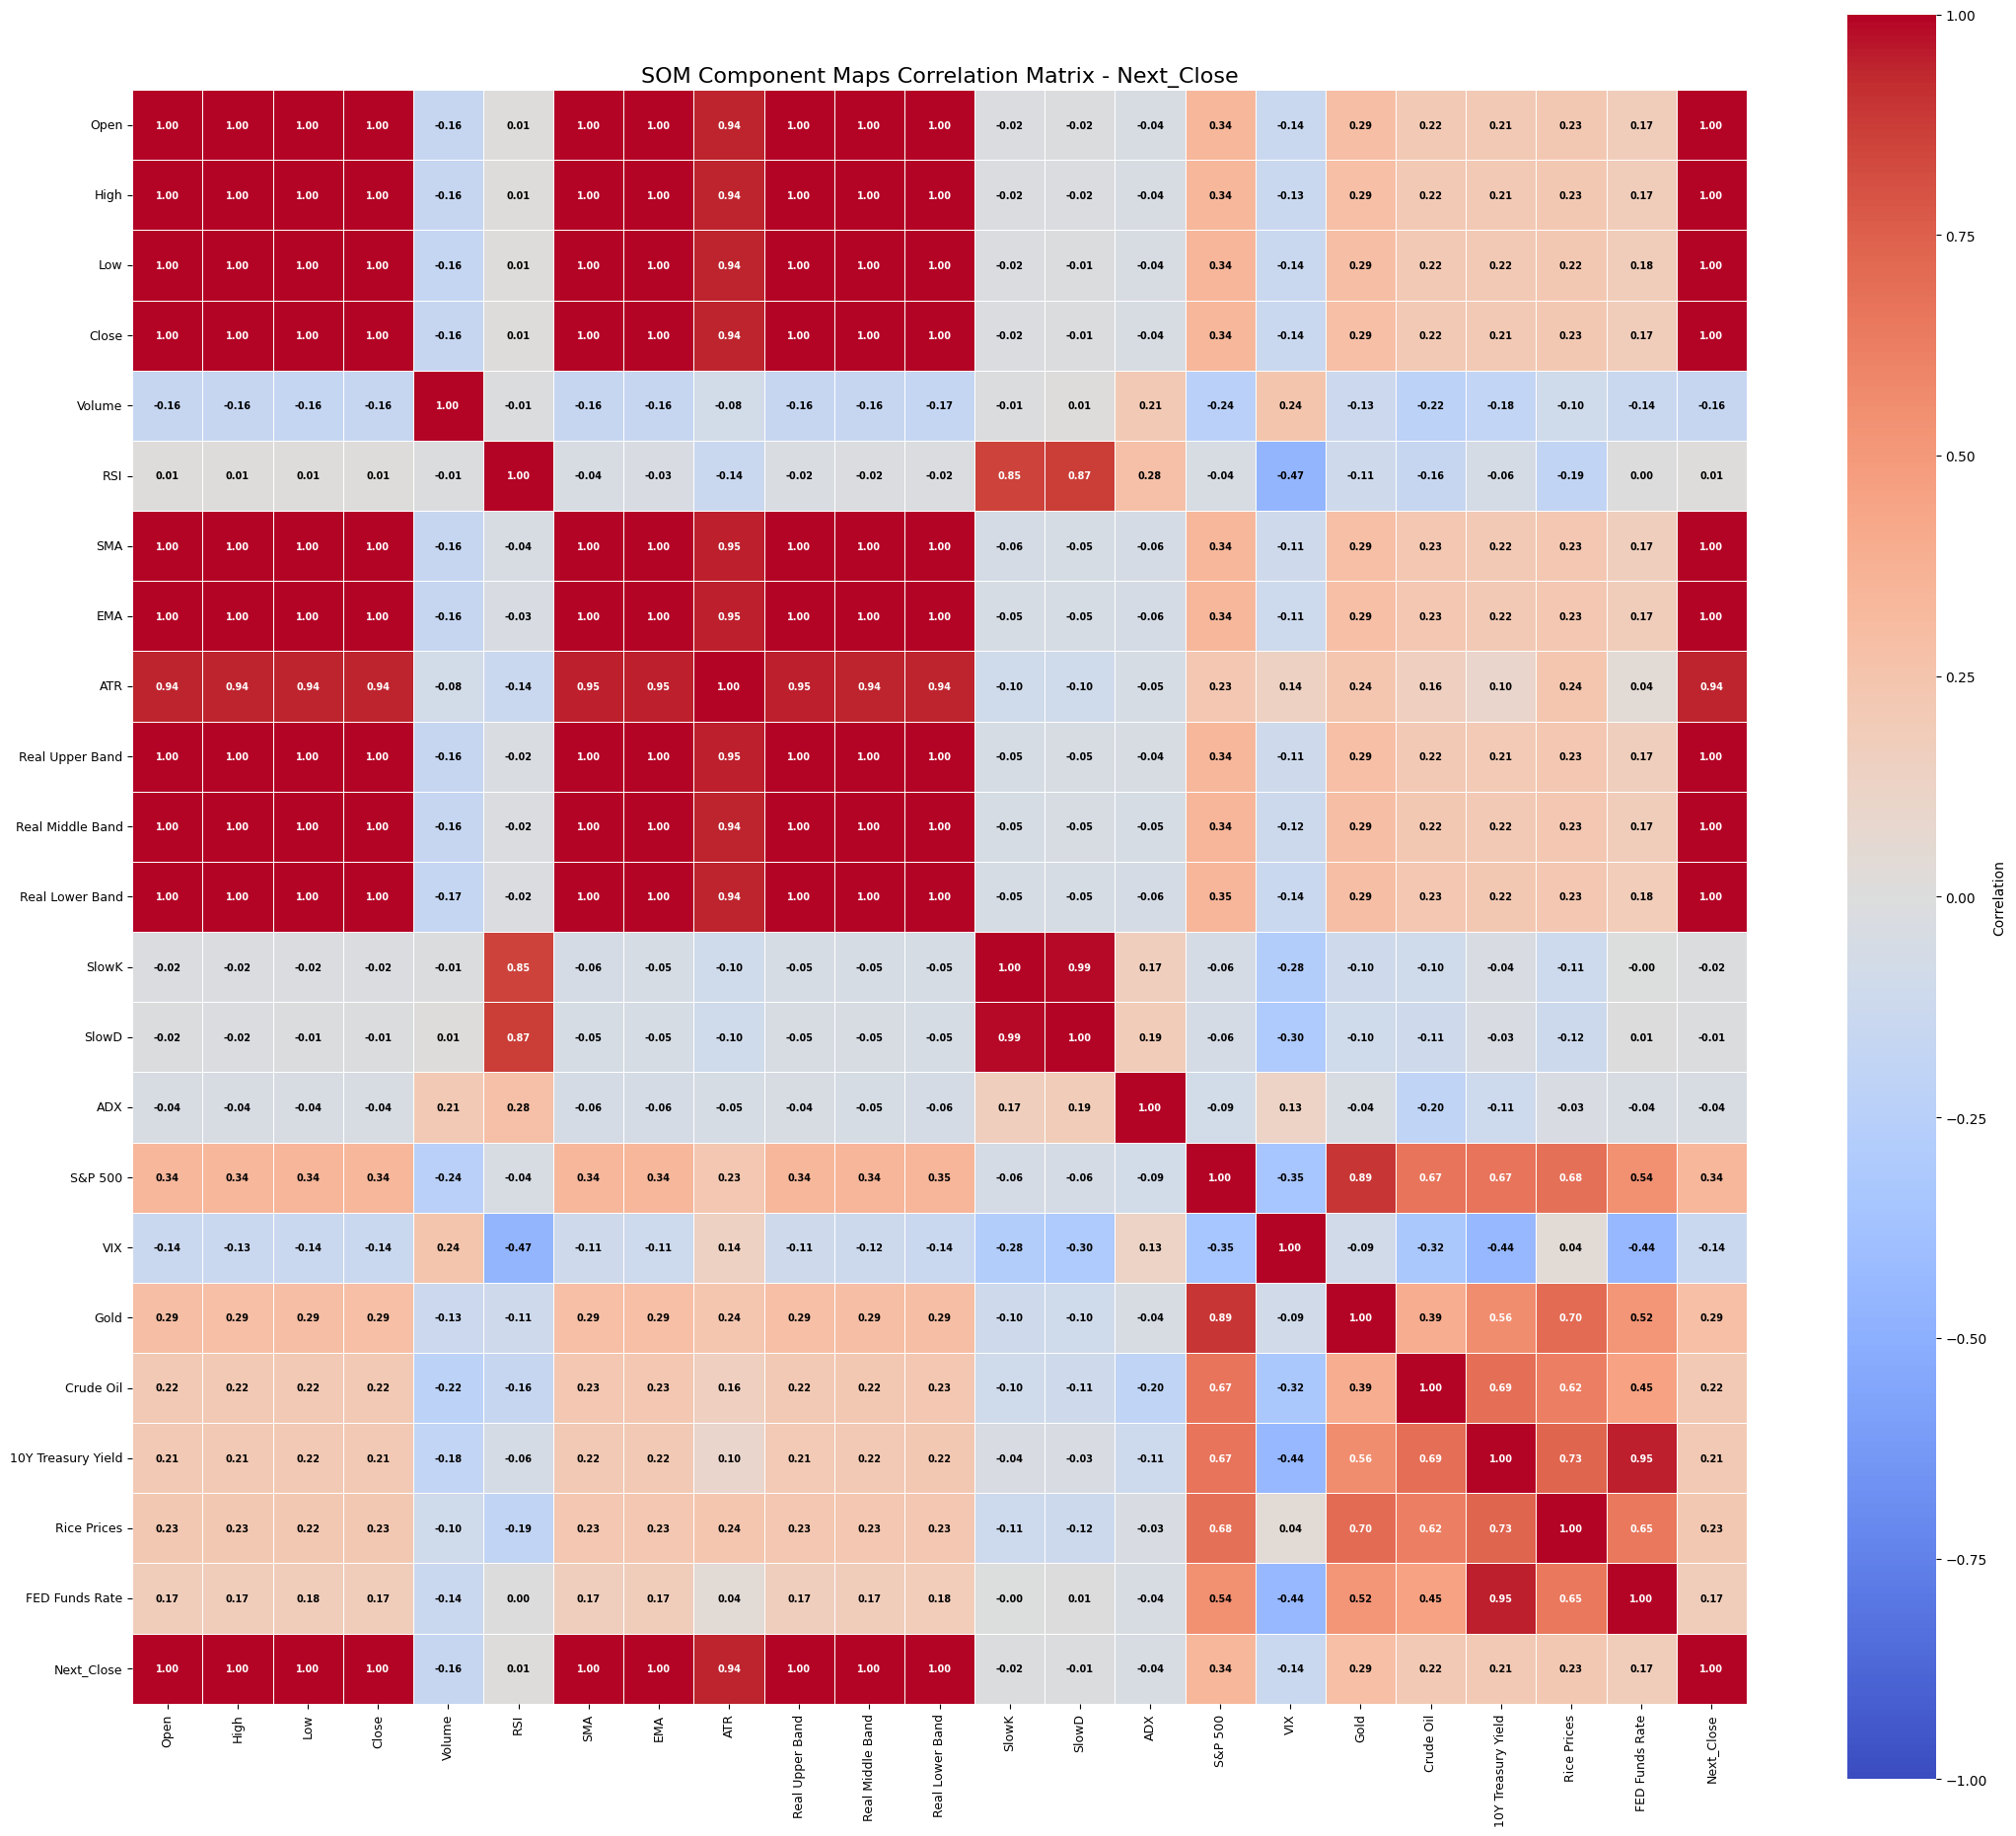


ΜΕΓΑΛΥΤΕΡΕΣ ΕΤΕΡΟΣΥΣΧΕΤΙΣΕΙΣ ΜΕΤΑΞΥ ΤΩΝ COMPONENT MAPS
          Variable_1        Variable_2  Correlation
0               Open              High     0.999989
1                Low             Close     0.999988
2               Open               Low     0.999986
3               High             Close     0.999986
4               Open             Close     0.999982
5              Close        Next_Close     0.999980
6               High               Low     0.999970
7                Low        Next_Close     0.999968
8               High        Next_Close     0.999962
9               Open        Next_Close     0.999960
10               SMA               EMA     0.999947
11   Real Upper Band  Real Middle Band     0.999762
12  Real Middle Band   Real Lower Band     0.999709
13               EMA   Real Upper Band     0.999696
14               EMA  Real Middle Band     0.999659
15               SMA   Real Upper Band     0.999552
16               SMA  Real Middle Band     0.999461
17      

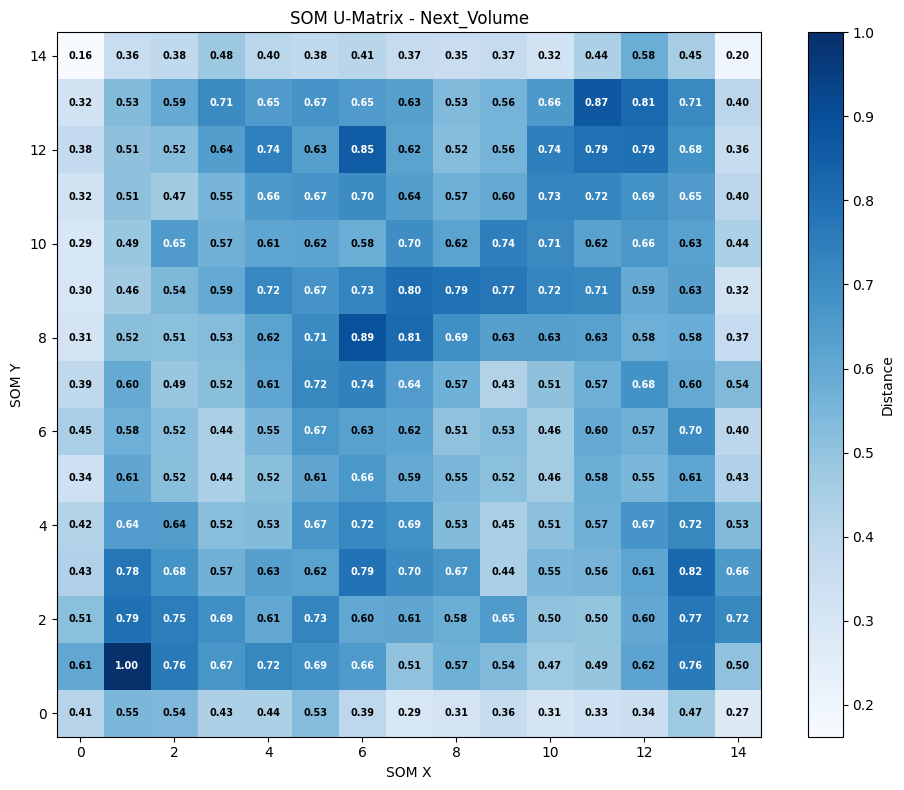


Διαστάσεις SOM weights: (15, 15, 23)
Αριθμός Component Maps: 23


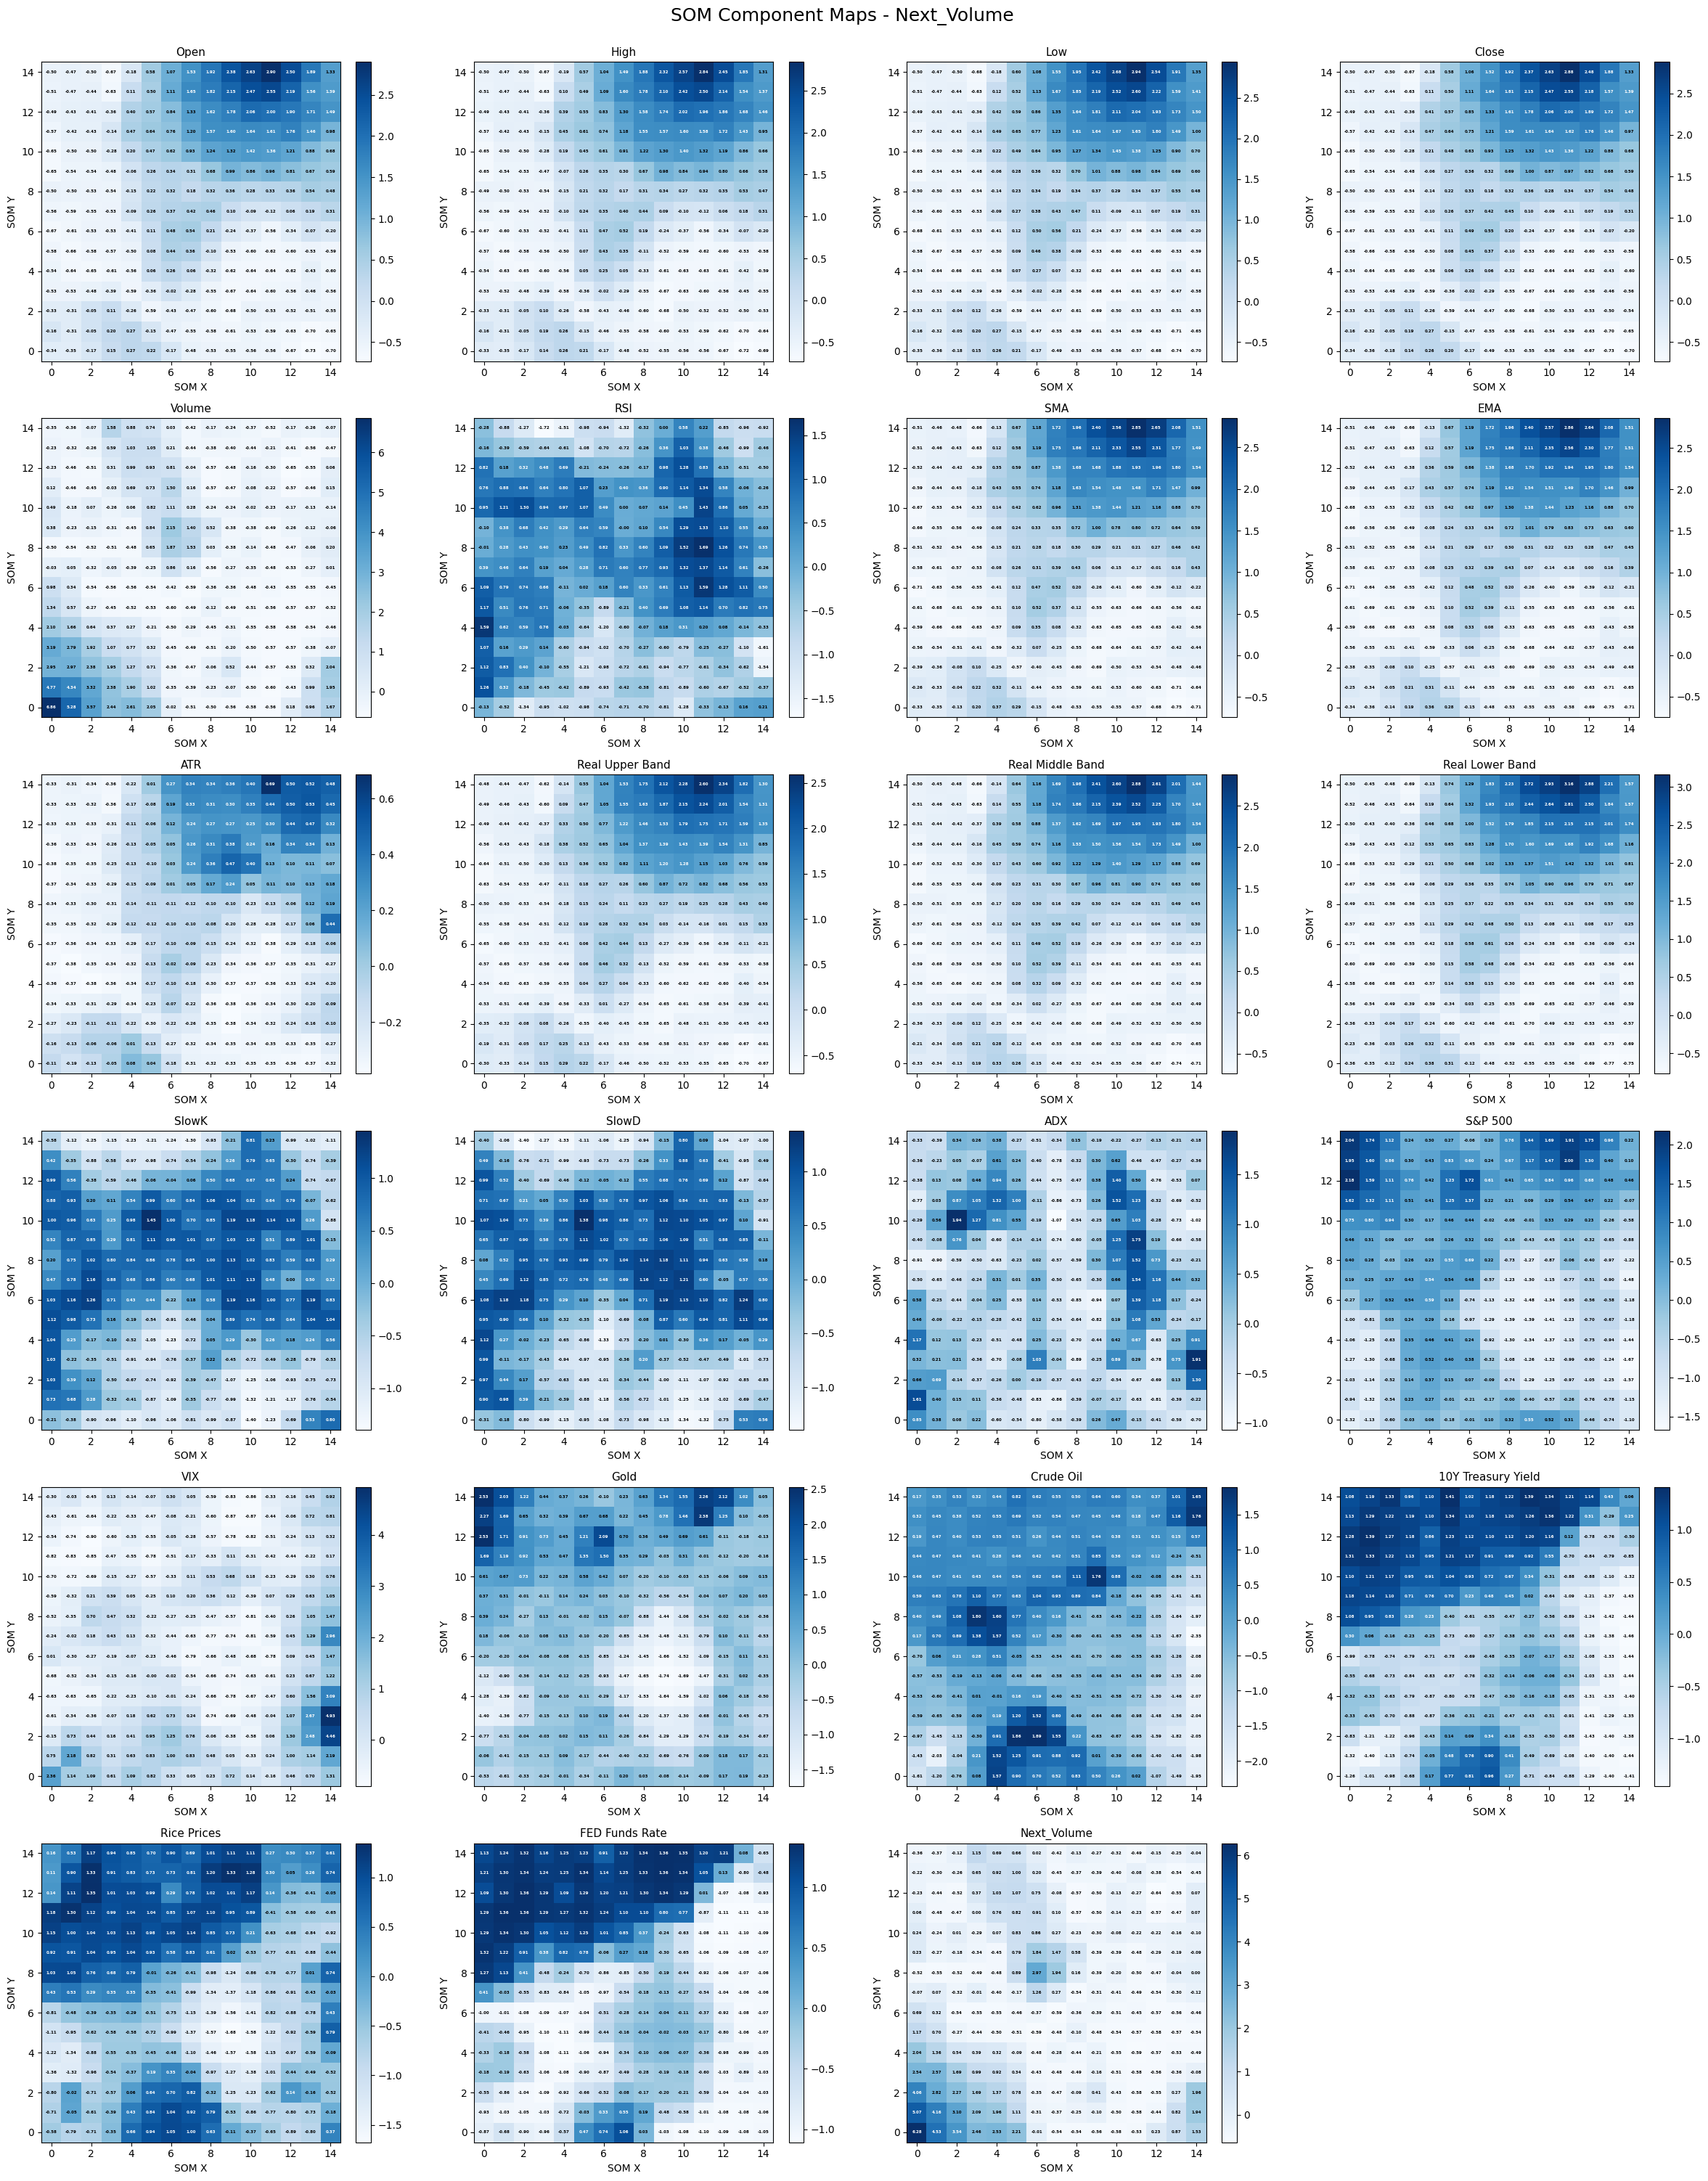

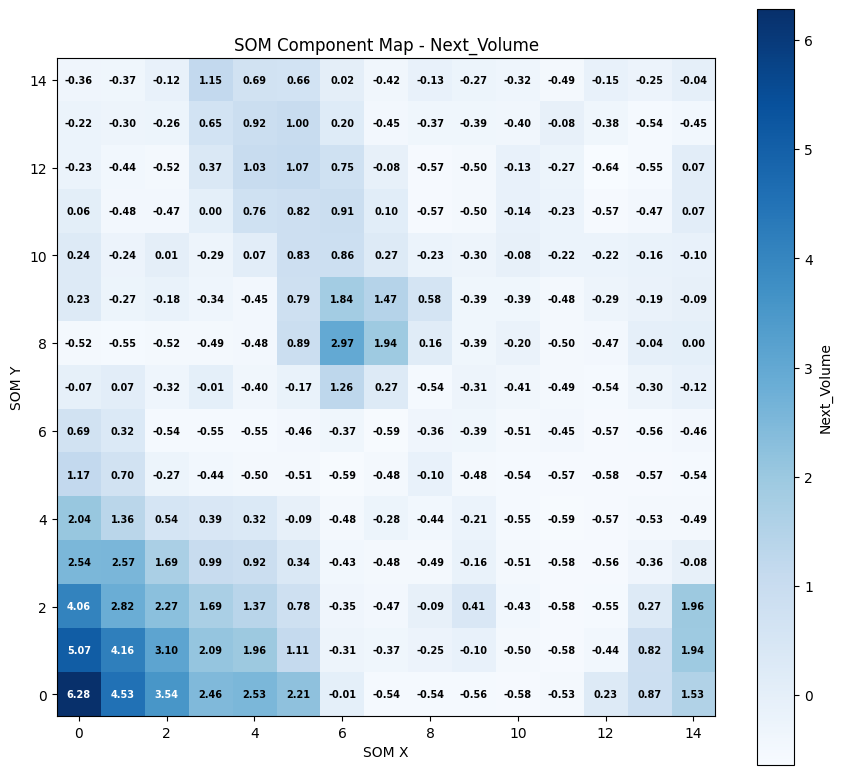


ΧΑΡΑΚΤΗΡΙΣΤΙΚΑ ΜΕ ΤΗ ΜΕΓΑΛΥΤΕΡΗ ΣΥΣΧΕΤΙΣΗ ΜΕ Next_Volume
               Feature  Correlation  Absolute_Correlation
0               Volume     0.989444              0.989444
1                  VIX     0.247966              0.247966
2            Crude Oil    -0.161306              0.161306
3   10Y Treasury Yield    -0.158200              0.158200
4                  ADX     0.157420              0.157420
5              S&P 500    -0.154460              0.154460
6      Real Lower Band    -0.140868              0.140868
7                  Low    -0.139293              0.139293
8                Close    -0.138460              0.138460
9                 Open    -0.137941              0.137941
10                 EMA    -0.137701              0.137701
11                High    -0.137358              0.137358
12    Real Middle Band    -0.136854              0.136854
13                 SMA    -0.136556              0.136556
14     Real Upper Band    -0.133165              0.133165
15      FED Fu

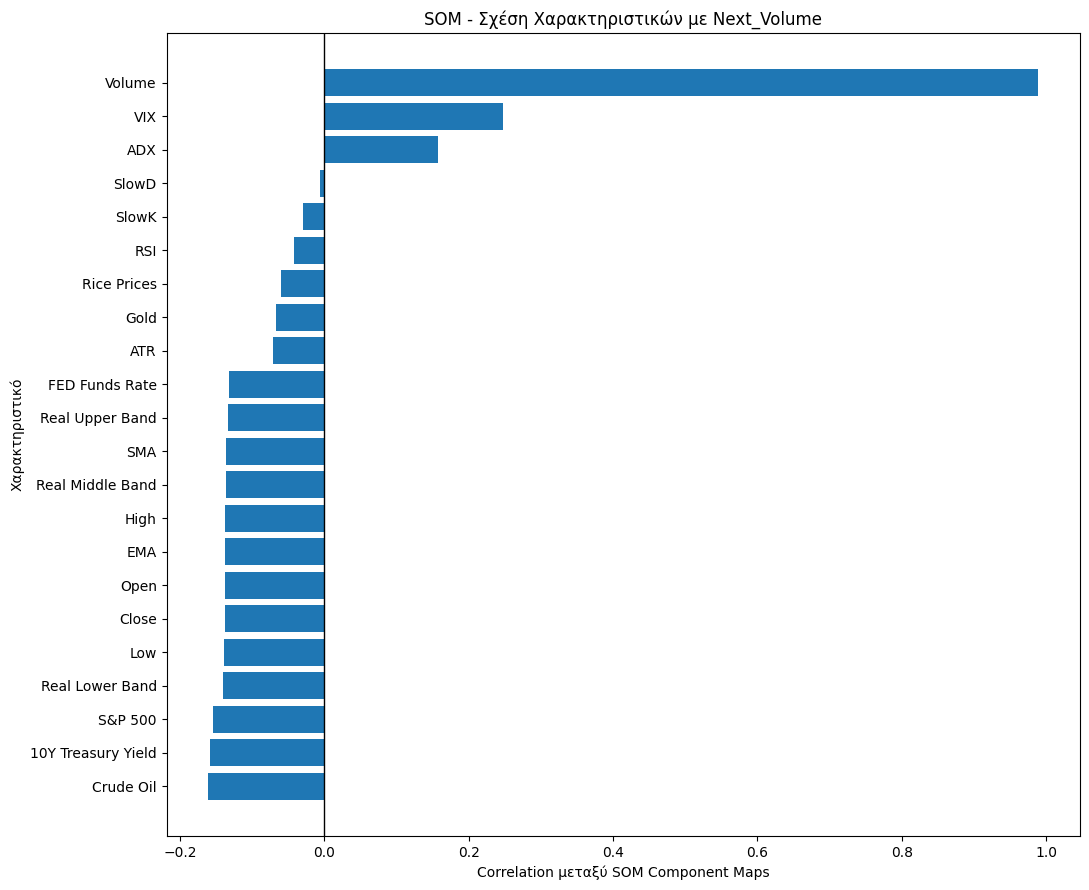


TOP 10 ΧΑΡΑΚΤΗΡΙΣΤΙΚΑ ΓΙΑ Next_Volume
              Feature  Correlation  Absolute_Correlation
0              Volume     0.989444              0.989444
1                 VIX     0.247966              0.247966
2           Crude Oil    -0.161306              0.161306
3  10Y Treasury Yield    -0.158200              0.158200
4                 ADX     0.157420              0.157420
5             S&P 500    -0.154460              0.154460
6     Real Lower Band    -0.140868              0.140868
7                 Low    -0.139293              0.139293
8               Close    -0.138460              0.138460
9                Open    -0.137941              0.137941


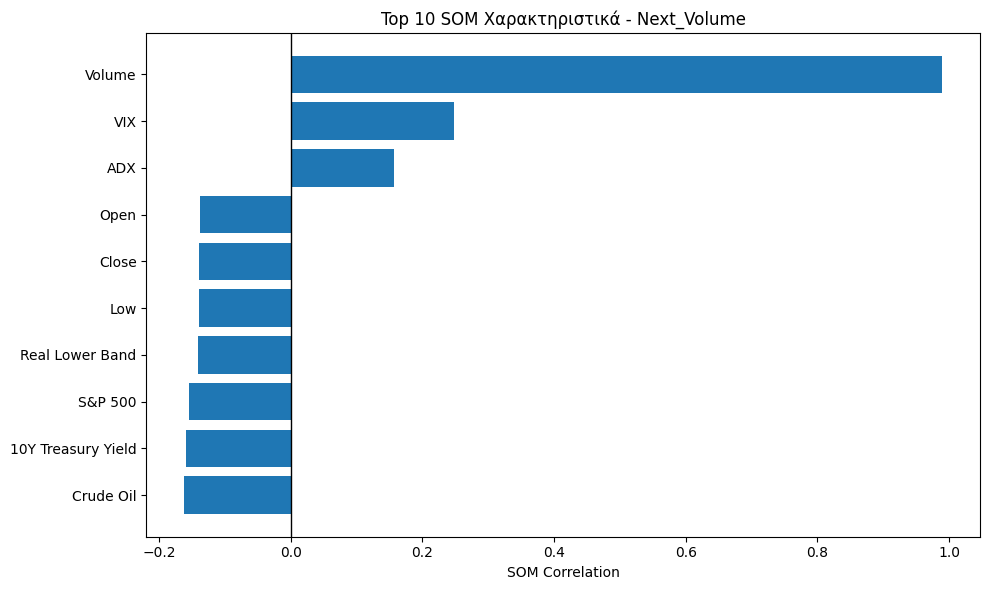


ΠΛΗΡΗΣ ΠΙΝΑΚΑΣ ΣΥΣΧΕΤΙΣΕΩΝ SOM COMPONENT MAPS
                    Open  High   Low  Close  Volume   RSI   SMA   EMA   ATR  \
Open                1.00  1.00  1.00   1.00   -0.15  0.07  1.00  1.00  0.95   
High                1.00  1.00  1.00   1.00   -0.15  0.07  1.00  1.00  0.95   
Low                 1.00  1.00  1.00   1.00   -0.15  0.07  1.00  1.00  0.94   
Close               1.00  1.00  1.00   1.00   -0.15  0.07  1.00  1.00  0.95   
Volume             -0.15 -0.15 -0.15  -0.15    1.00 -0.05 -0.15 -0.15 -0.08   
RSI                 0.07  0.07  0.07   0.07   -0.05  1.00  0.02  0.02 -0.06   
SMA                 1.00  1.00  1.00   1.00   -0.15  0.02  1.00  1.00  0.96   
EMA                 1.00  1.00  1.00   1.00   -0.15  0.02  1.00  1.00  0.95   
ATR                 0.95  0.95  0.94   0.95   -0.08 -0.06  0.96  0.95  1.00   
Real Upper Band     1.00  1.00  1.00   1.00   -0.14  0.03  1.00  1.00  0.95   
Real Middle Band    1.00  1.00  1.00   1.00   -0.15  0.03  1.00  1.00  0.95   
Real 

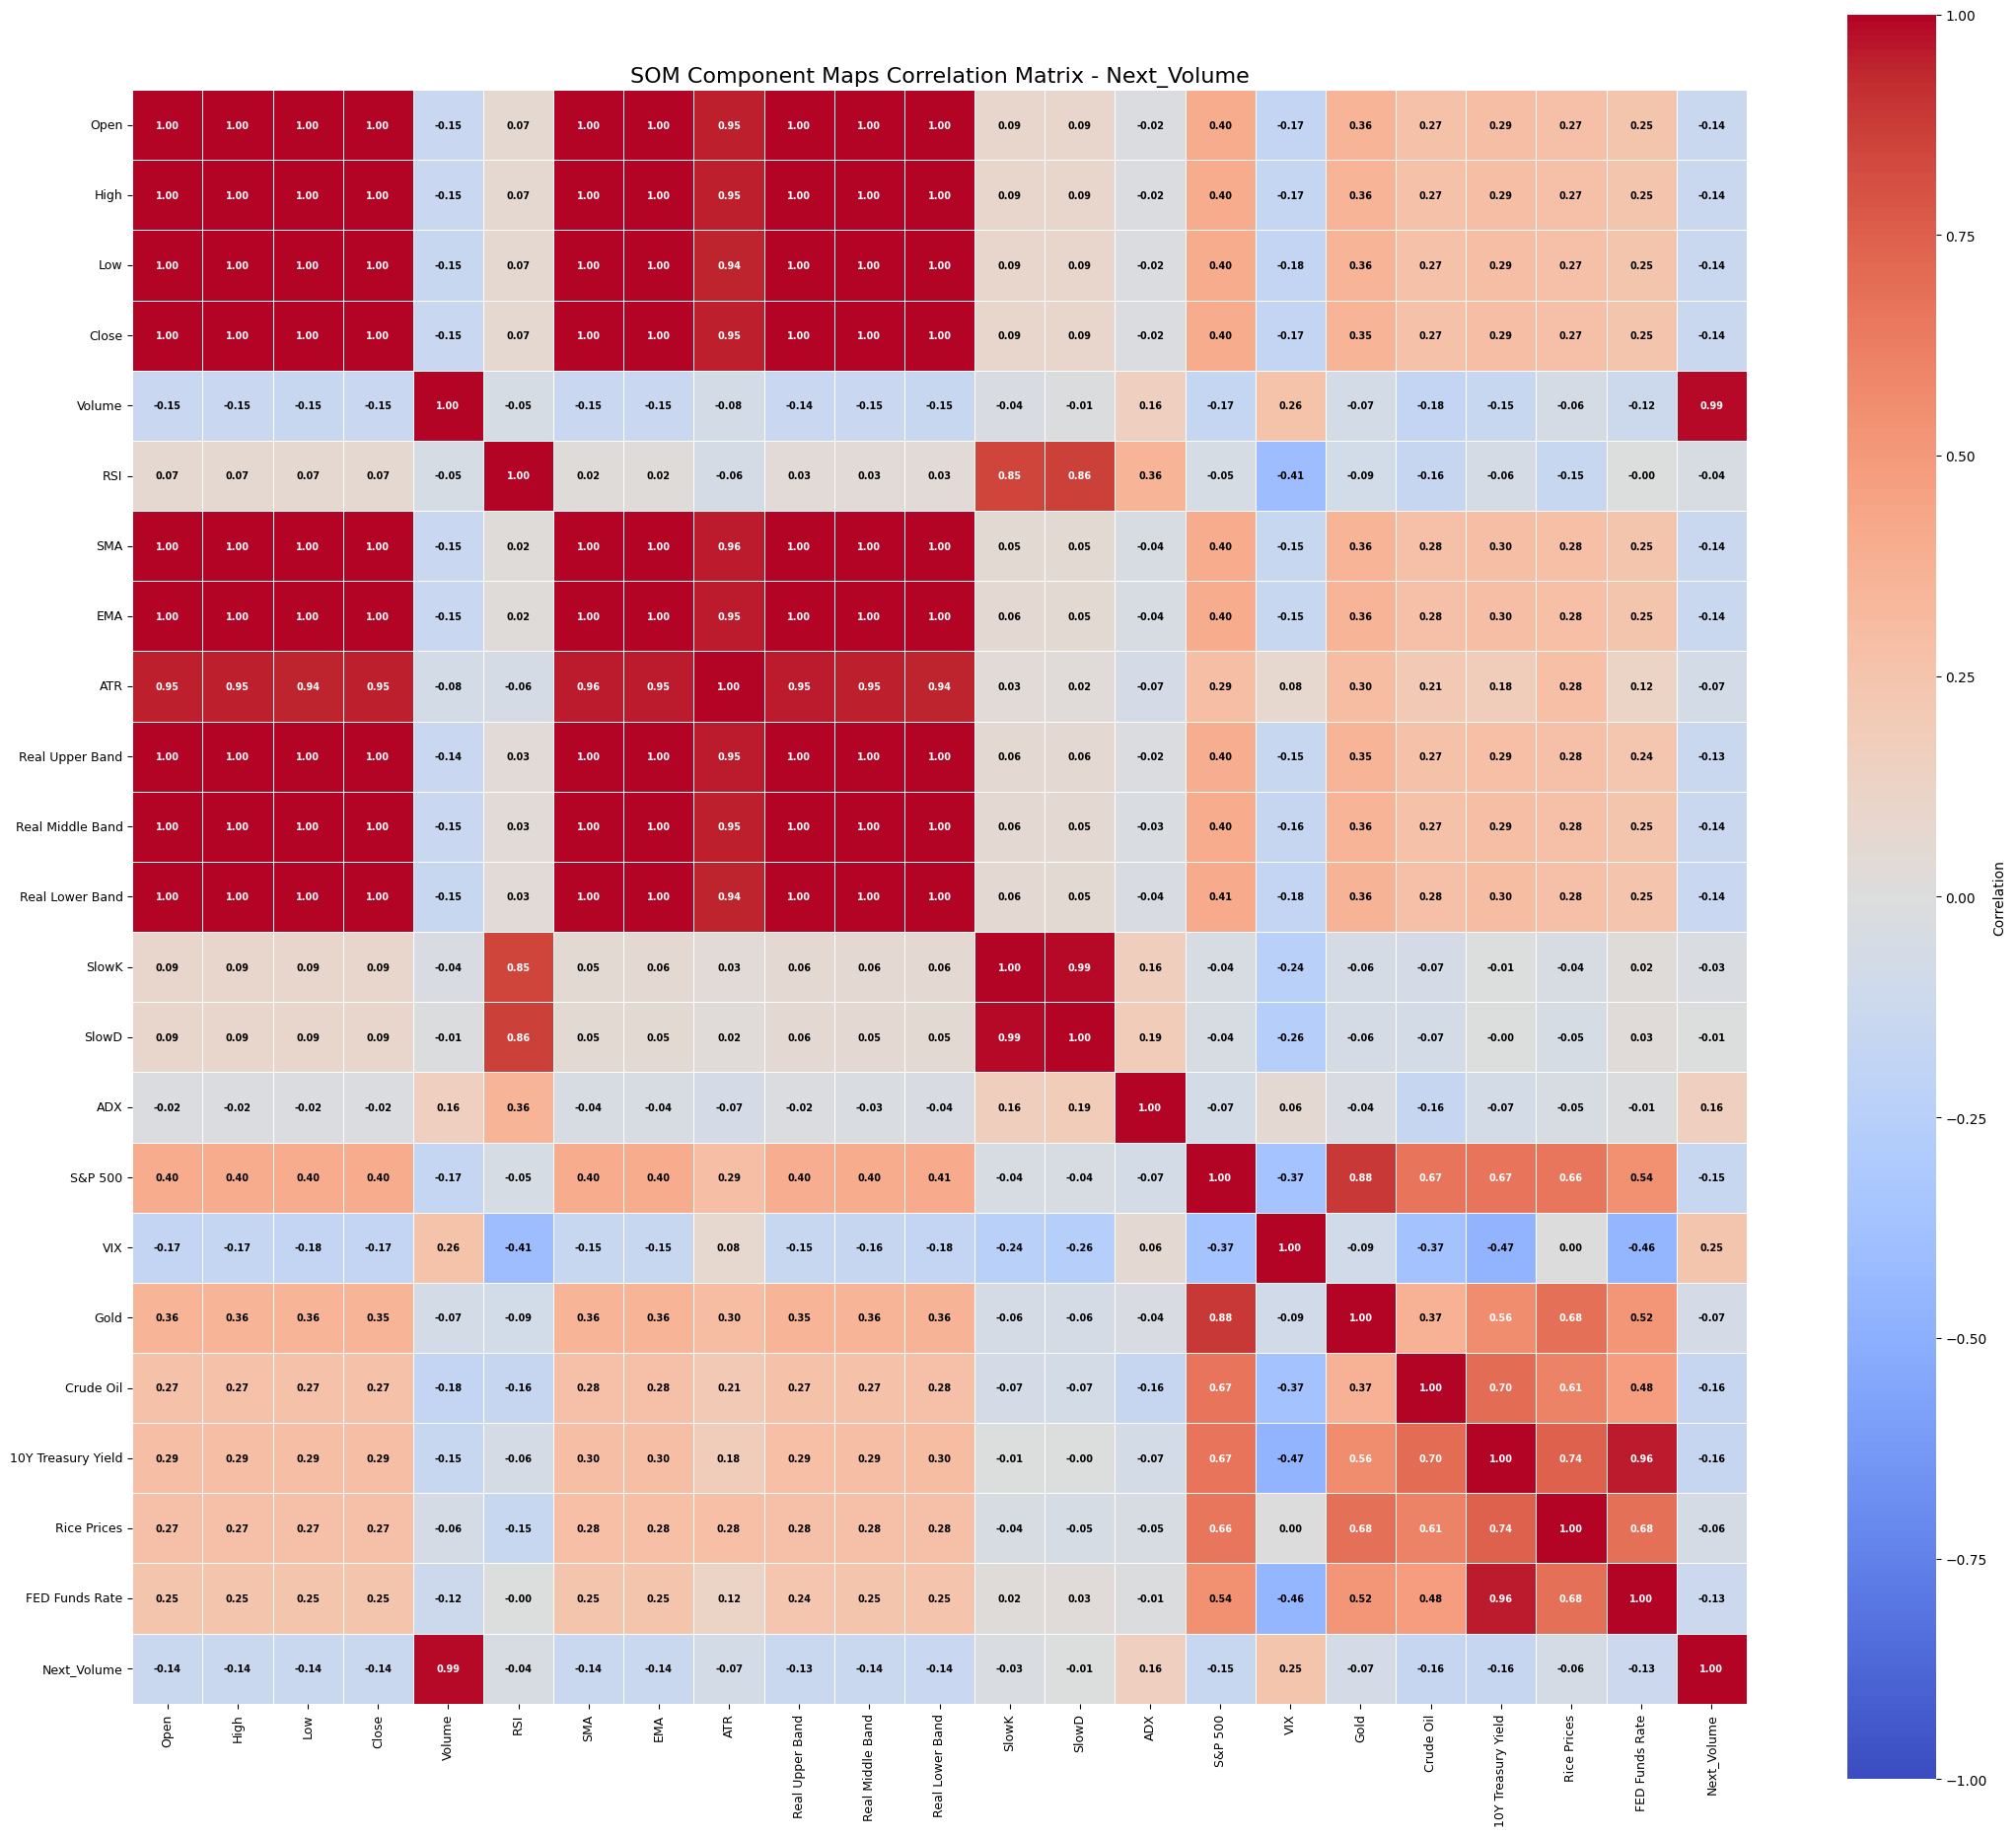


ΜΕΓΑΛΥΤΕΡΕΣ ΕΤΕΡΟΣΥΣΧΕΤΙΣΕΙΣ ΜΕΤΑΞΥ ΤΩΝ COMPONENT MAPS
          Variable_1        Variable_2  Correlation
0               Open              High     0.999991
1                Low             Close     0.999989
2               High             Close     0.999988
3               Open               Low     0.999988
4               Open             Close     0.999983
5               High               Low     0.999975
6                SMA               EMA     0.999954
7    Real Upper Band  Real Middle Band     0.999779
8   Real Middle Band   Real Lower Band     0.999729
9                EMA  Real Middle Band     0.999642
10               EMA   Real Upper Band     0.999629
11               SMA  Real Middle Band     0.999460
12               SMA   Real Upper Band     0.999451
13               EMA   Real Lower Band     0.999141
14              High  Real Middle Band     0.999091
15              Open  Real Middle Band     0.999087
16   Real Upper Band   Real Lower Band     0.999019
17      

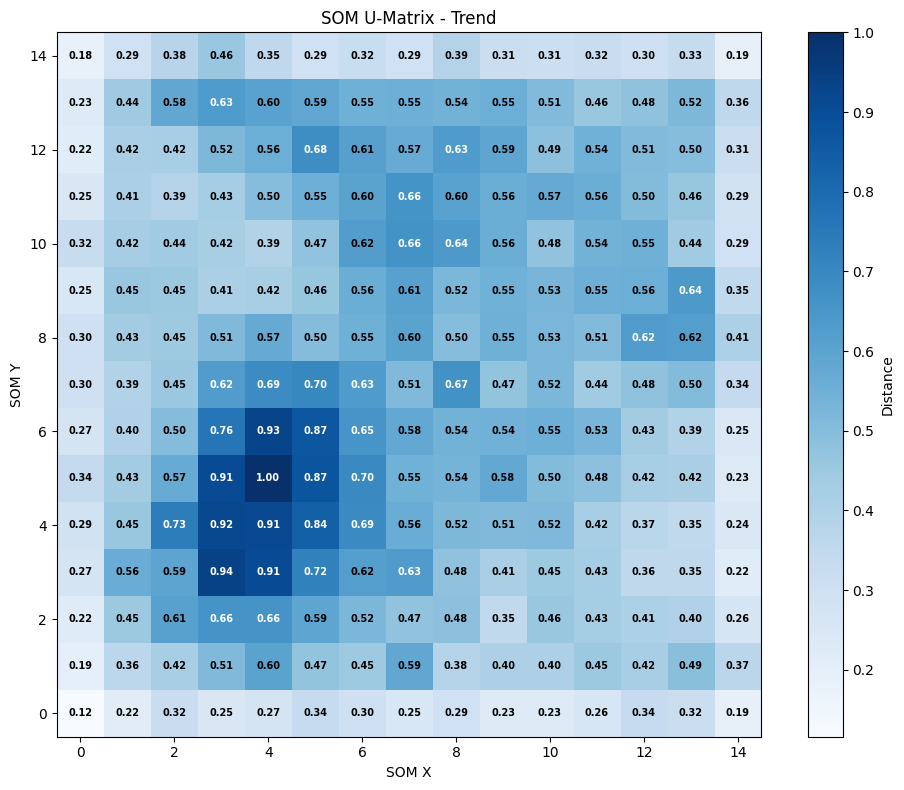


Διαστάσεις SOM weights: (15, 15, 23)
Αριθμός Component Maps: 23


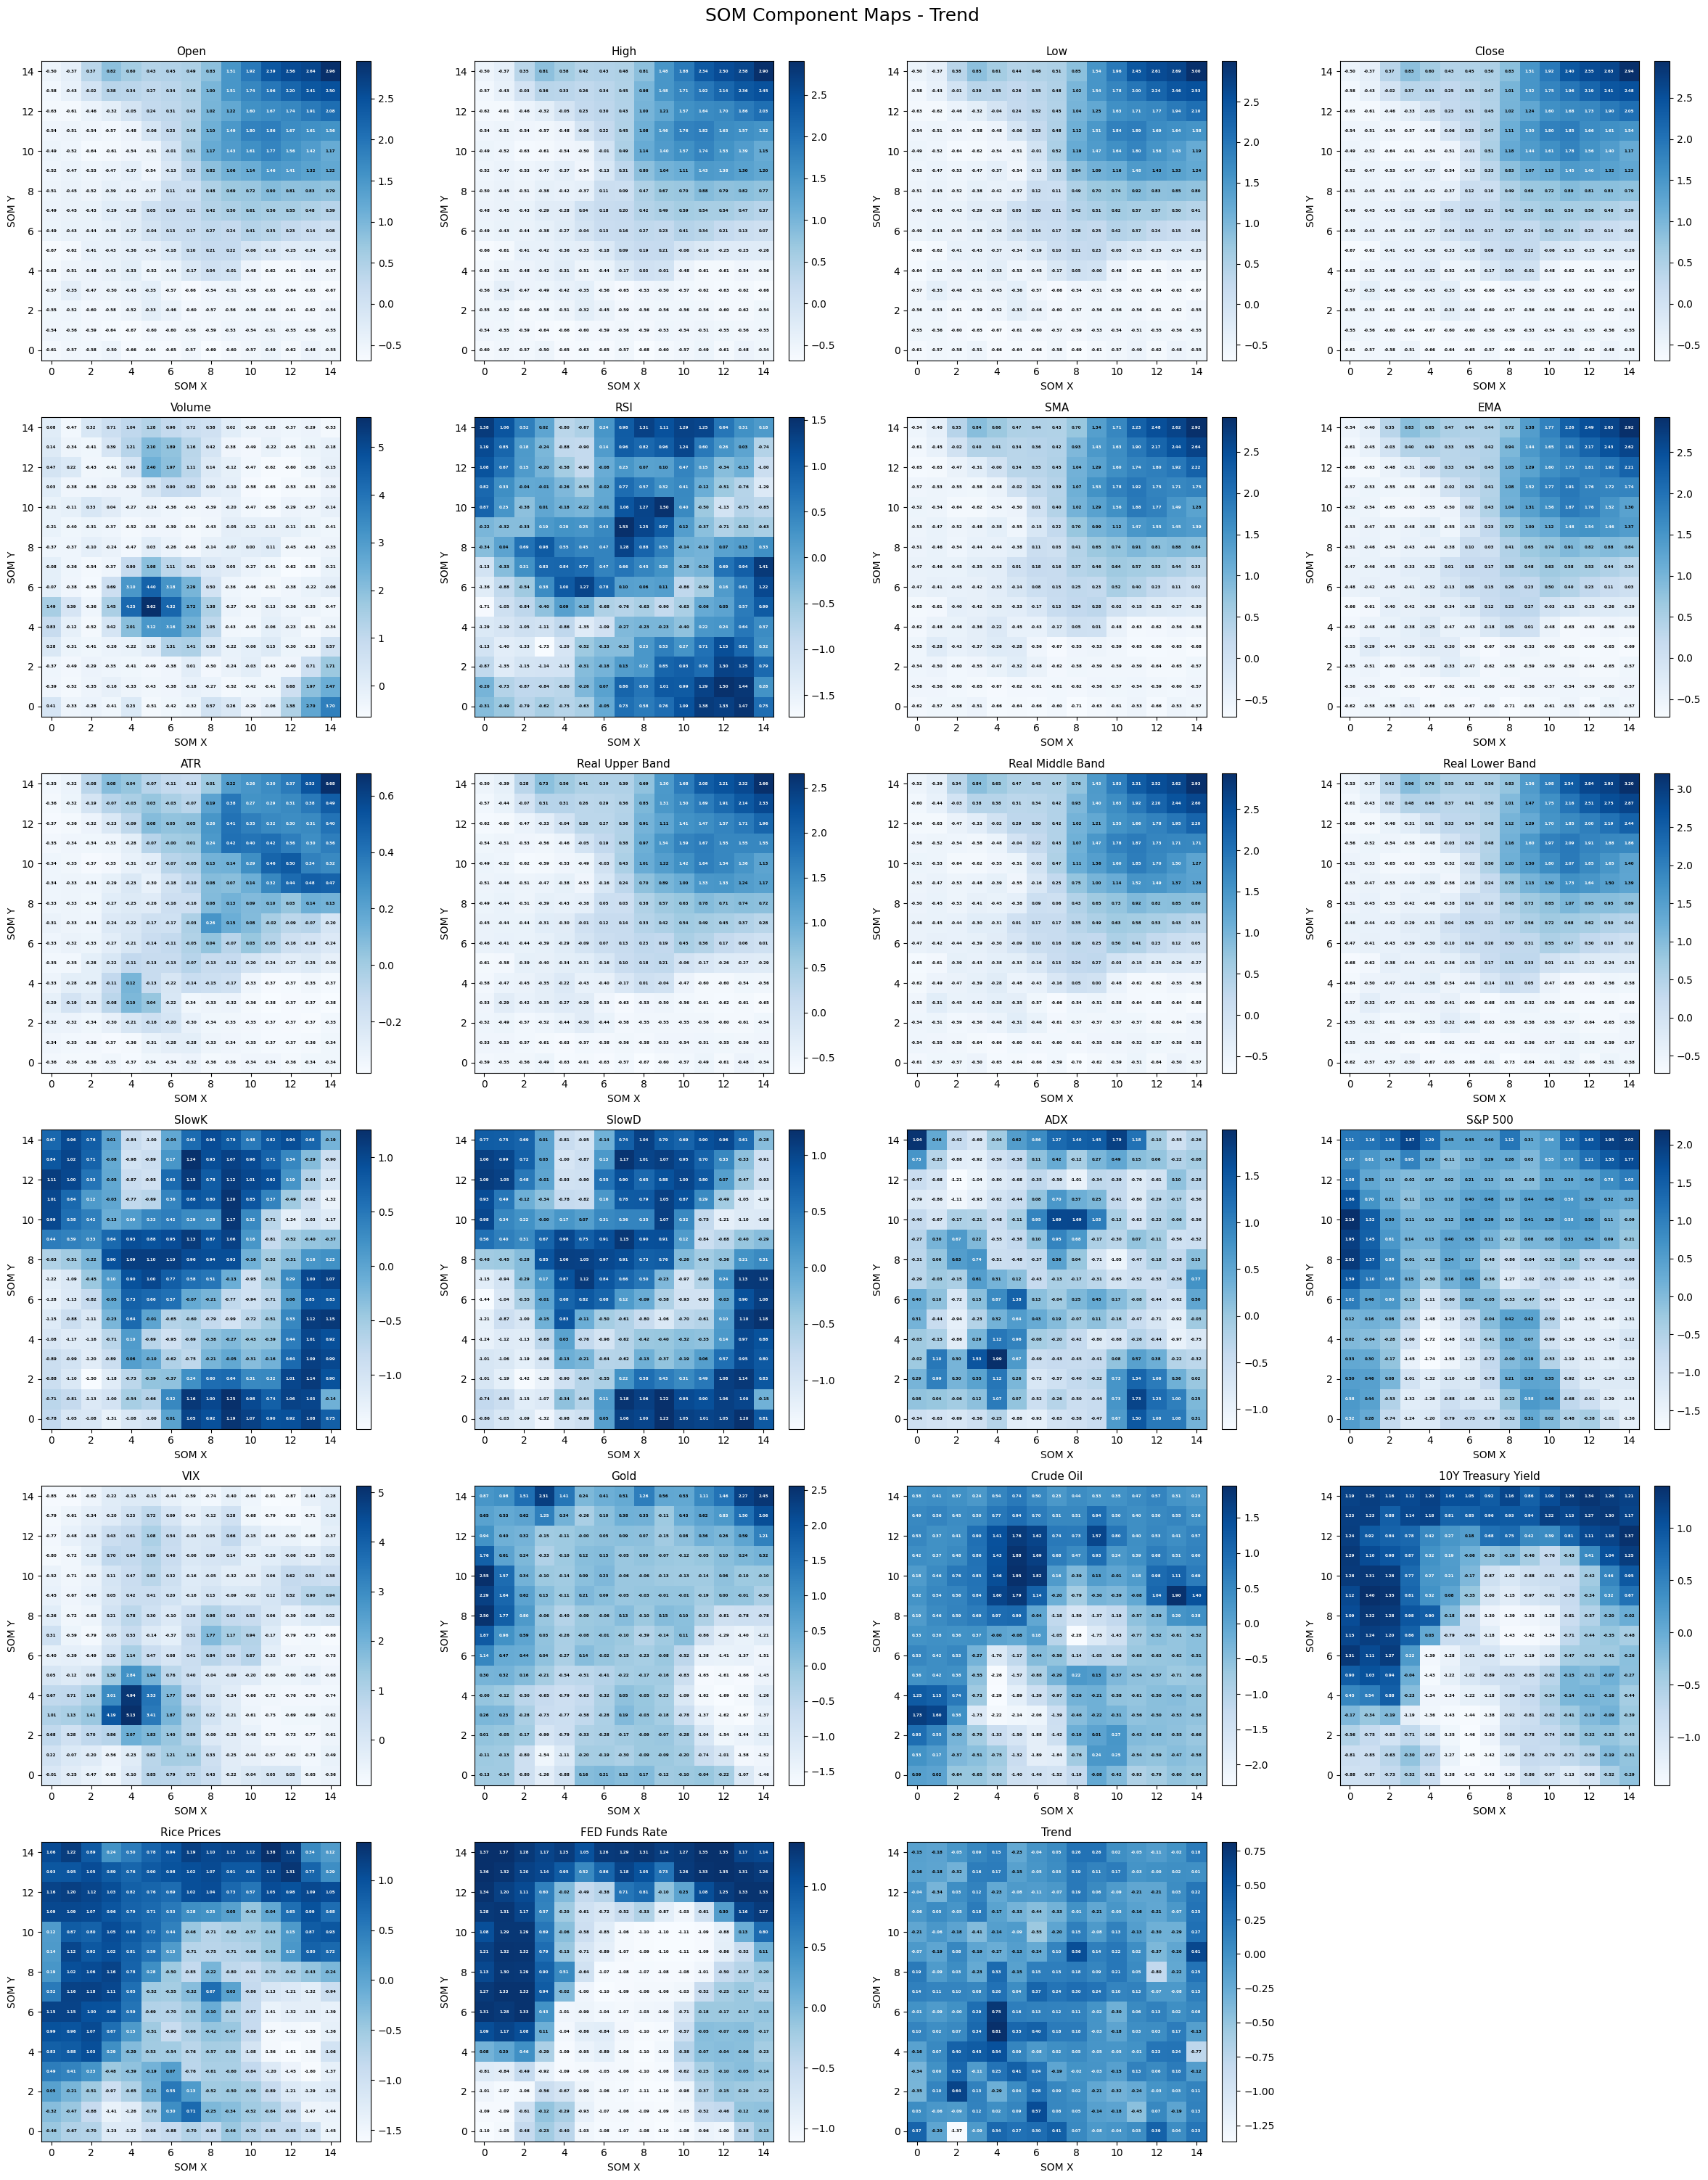

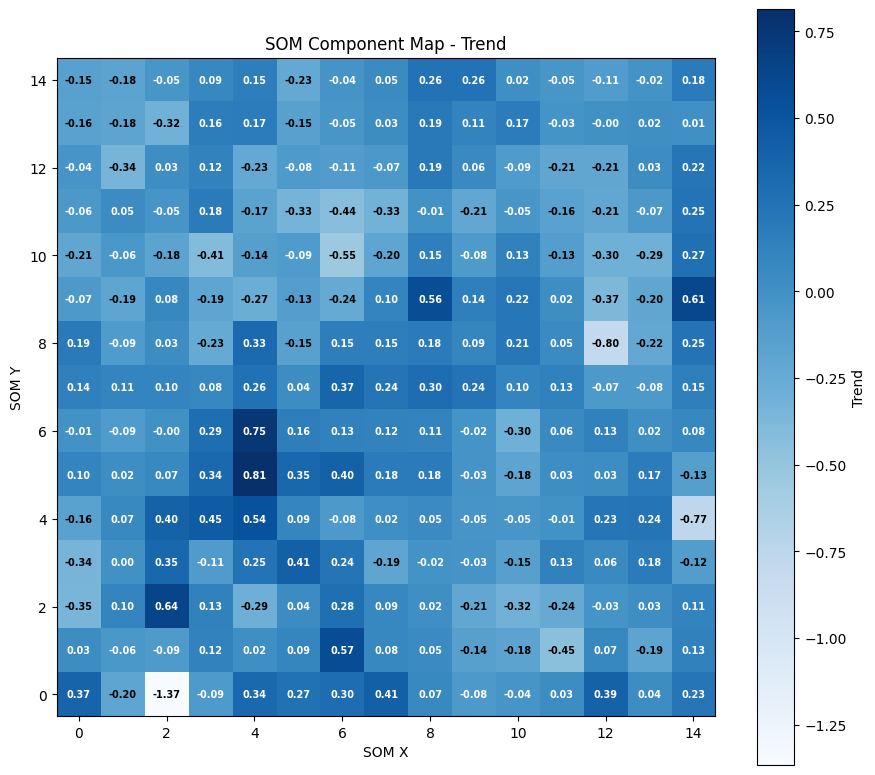


ΧΑΡΑΚΤΗΡΙΣΤΙΚΑ ΜΕ ΤΗ ΜΕΓΑΛΥΤΕΡΗ ΣΥΣΧΕΤΙΣΗ ΜΕ Trend
               Feature  Correlation  Absolute_Correlation
0            Crude Oil    -0.388817              0.388817
1                  VIX     0.307400              0.307400
2               Volume     0.259479              0.259479
3              S&P 500    -0.210302              0.210302
4   10Y Treasury Yield    -0.176399              0.176399
5       FED Funds Rate    -0.099475              0.099475
6          Rice Prices    -0.073467              0.073467
7                  ATR     0.052004              0.052004
8                 Gold    -0.041410              0.041410
9                  ADX     0.039927              0.039927
10     Real Lower Band    -0.019340              0.019340
11                 EMA    -0.015262              0.015262
12                 SMA    -0.015001              0.015001
13    Real Middle Band    -0.013987              0.013987
14                 Low    -0.010959              0.010959
15                Op

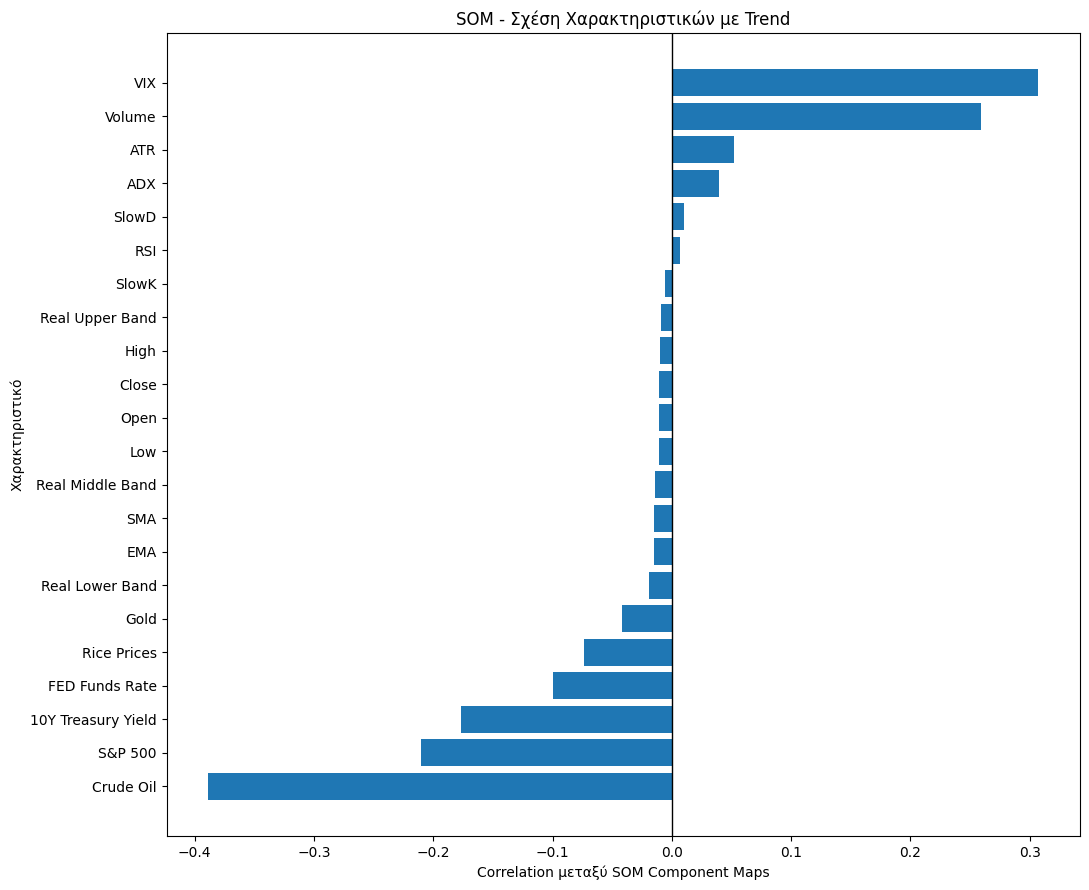


TOP 10 ΧΑΡΑΚΤΗΡΙΣΤΙΚΑ ΓΙΑ Trend
              Feature  Correlation  Absolute_Correlation
0           Crude Oil    -0.388817              0.388817
1                 VIX     0.307400              0.307400
2              Volume     0.259479              0.259479
3             S&P 500    -0.210302              0.210302
4  10Y Treasury Yield    -0.176399              0.176399
5      FED Funds Rate    -0.099475              0.099475
6         Rice Prices    -0.073467              0.073467
7                 ATR     0.052004              0.052004
8                Gold    -0.041410              0.041410
9                 ADX     0.039927              0.039927


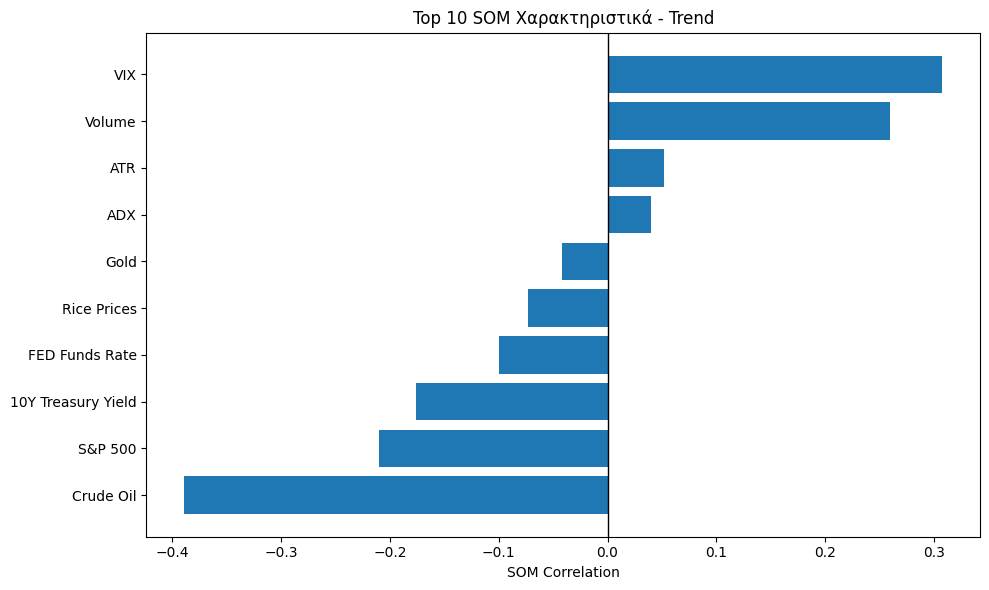


ΠΛΗΡΗΣ ΠΙΝΑΚΑΣ ΣΥΣΧΕΤΙΣΕΩΝ SOM COMPONENT MAPS
                    Open  High   Low  Close  Volume   RSI   SMA   EMA   ATR  \
Open                1.00  1.00  1.00   1.00   -0.16  0.06  1.00  1.00  0.94   
High                1.00  1.00  1.00   1.00   -0.16  0.06  1.00  1.00  0.94   
Low                 1.00  1.00  1.00   1.00   -0.16  0.07  1.00  1.00  0.94   
Close               1.00  1.00  1.00   1.00   -0.16  0.06  1.00  1.00  0.94   
Volume             -0.16 -0.16 -0.16  -0.16    1.00 -0.01 -0.16 -0.16 -0.08   
RSI                 0.06  0.06  0.07   0.06   -0.01  1.00  0.01  0.02 -0.08   
SMA                 1.00  1.00  1.00   1.00   -0.16  0.01  1.00  1.00  0.95   
EMA                 1.00  1.00  1.00   1.00   -0.16  0.02  1.00  1.00  0.95   
ATR                 0.94  0.94  0.94   0.94   -0.08 -0.08  0.95  0.95  1.00   
Real Upper Band     1.00  1.00  1.00   1.00   -0.15  0.03  1.00  1.00  0.95   
Real Middle Band    1.00  1.00  1.00   1.00   -0.16  0.03  1.00  1.00  0.95   
Real 

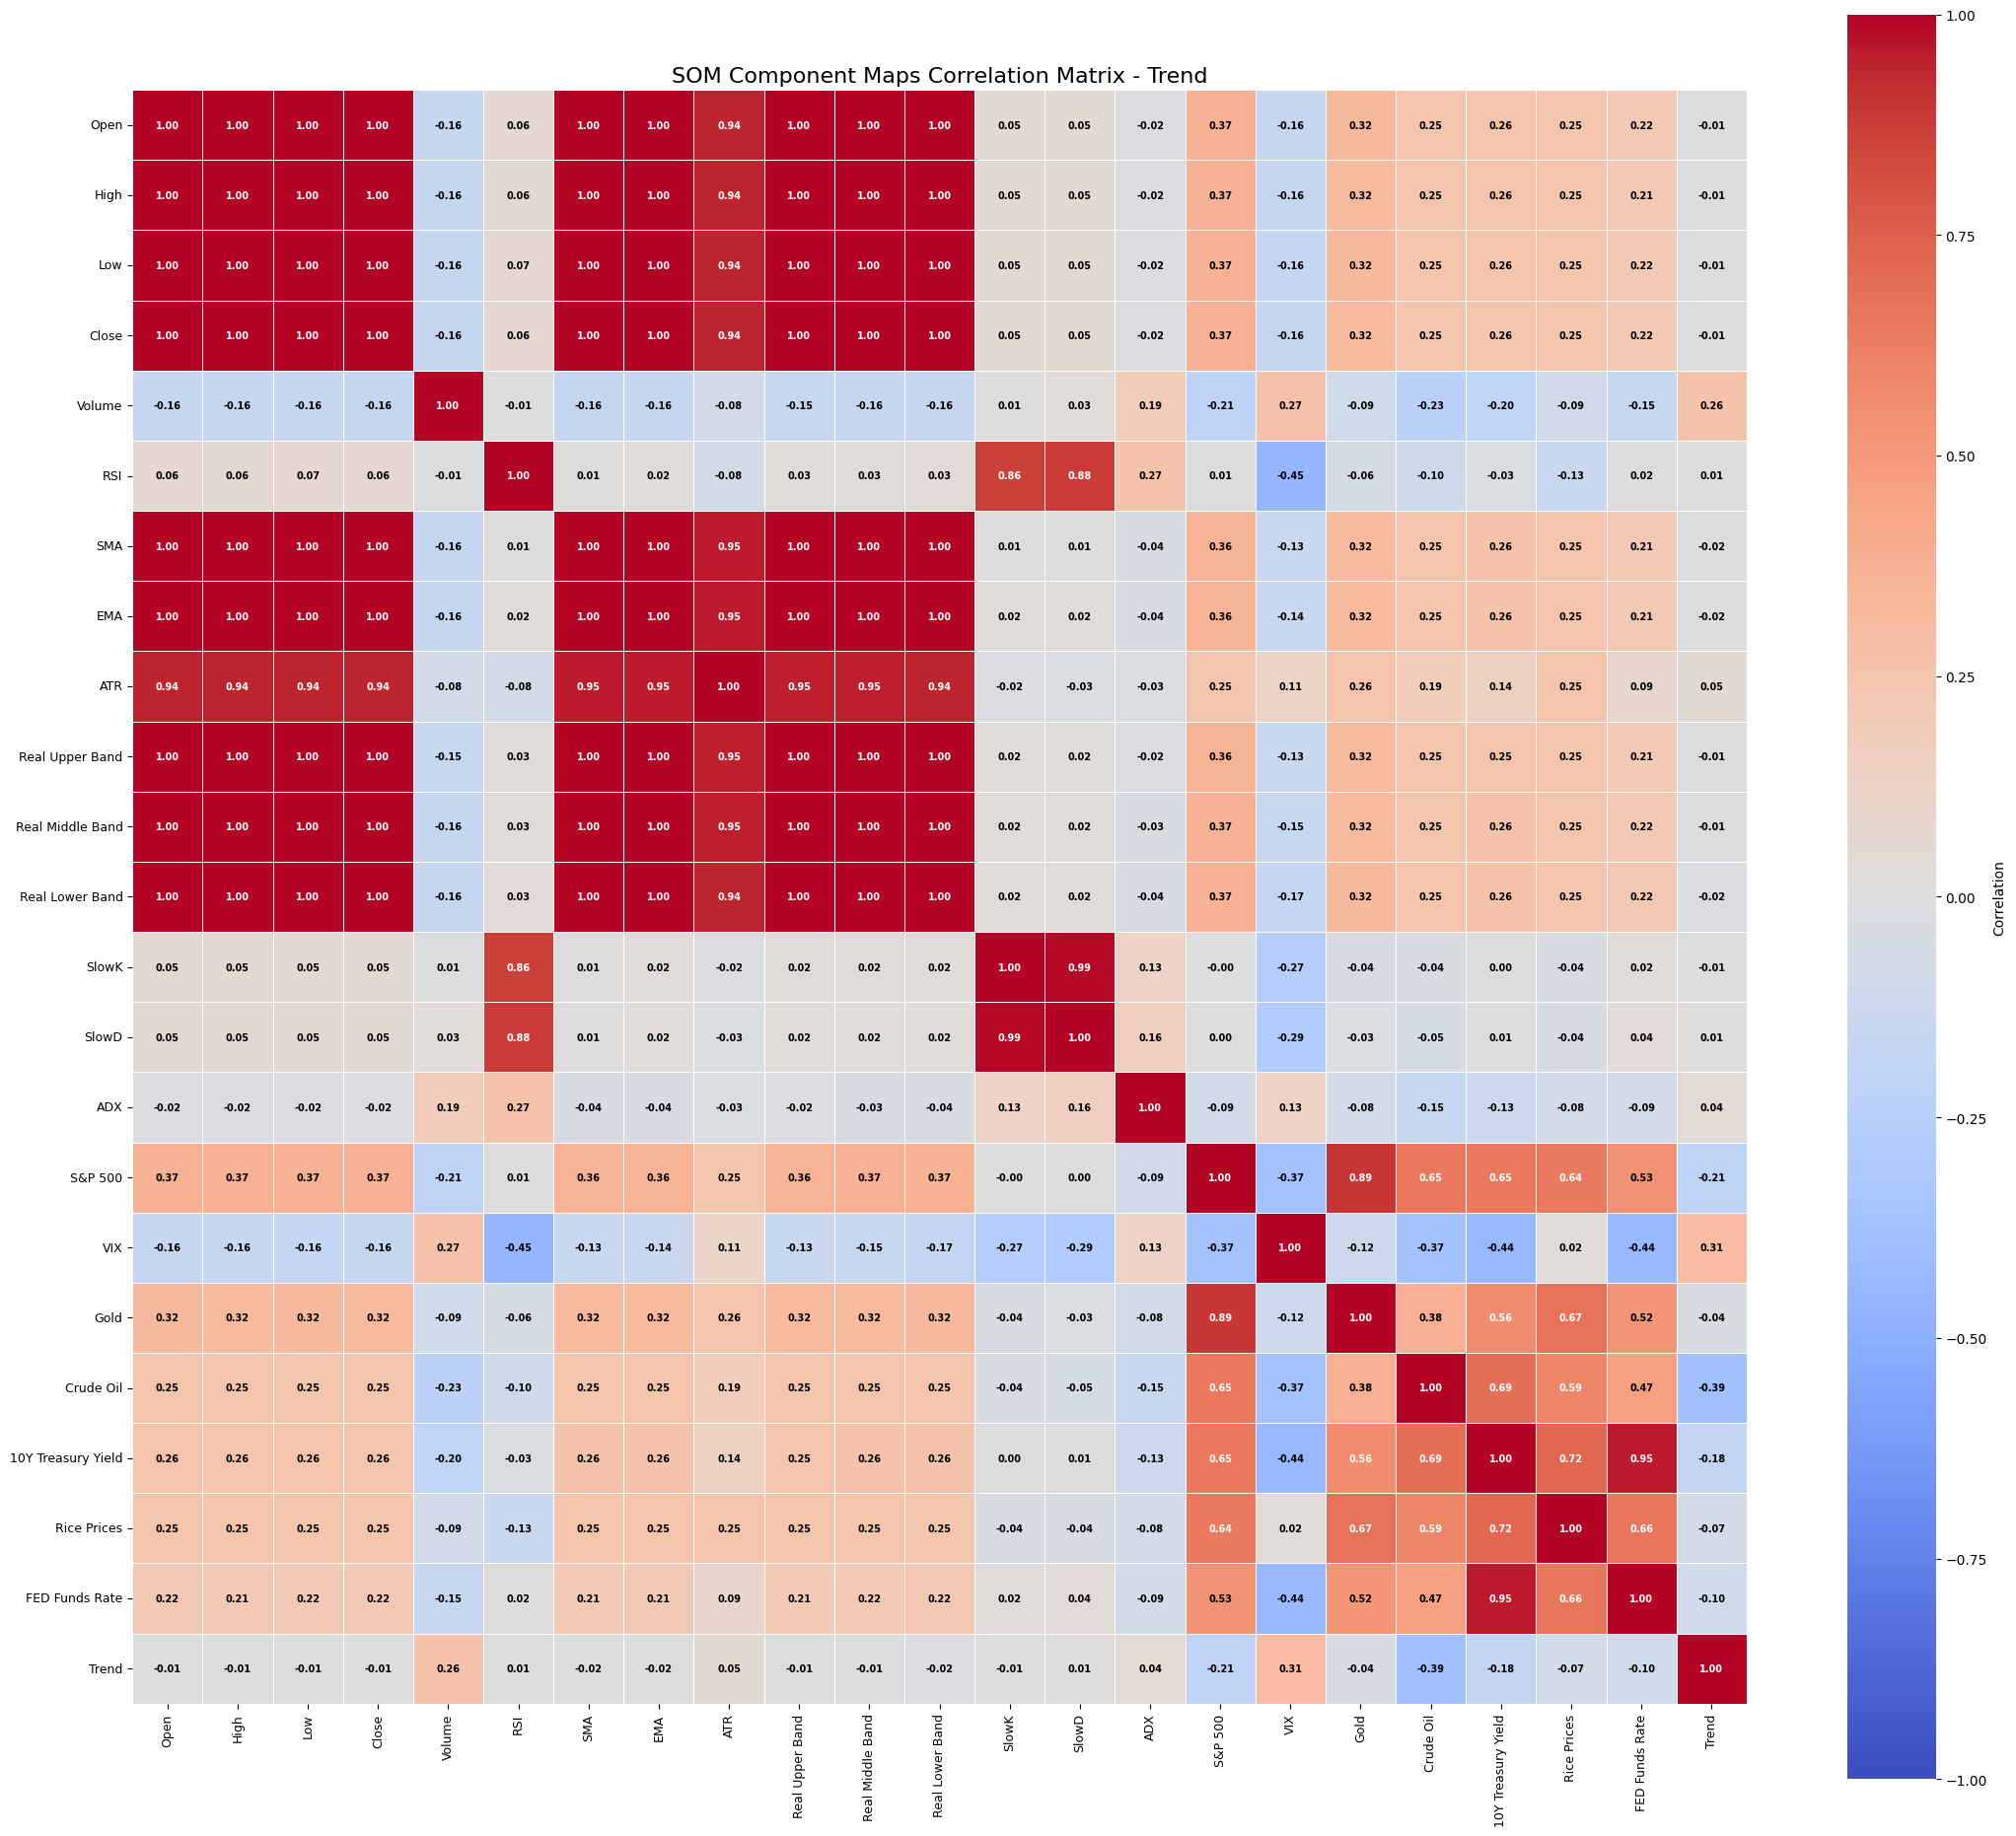


ΜΕΓΑΛΥΤΕΡΕΣ ΕΤΕΡΟΣΥΣΧΕΤΙΣΕΙΣ ΜΕΤΑΞΥ ΤΩΝ COMPONENT MAPS
          Variable_1        Variable_2  Correlation
0               Open              High     0.999990
1                Low             Close     0.999989
2               Open               Low     0.999987
3               High             Close     0.999987
4               Open             Close     0.999982
5               High               Low     0.999974
6                SMA               EMA     0.999942
7    Real Upper Band  Real Middle Band     0.999723
8   Real Middle Band   Real Lower Band     0.999661
9                EMA  Real Middle Band     0.999654
10               EMA   Real Upper Band     0.999610
11               SMA  Real Middle Band     0.999437
12               SMA   Real Upper Band     0.999403
13              Open  Real Middle Band     0.999080
14              High  Real Middle Band     0.999075
15               EMA   Real Lower Band     0.999058
16              High   Real Upper Band     0.998939
17      

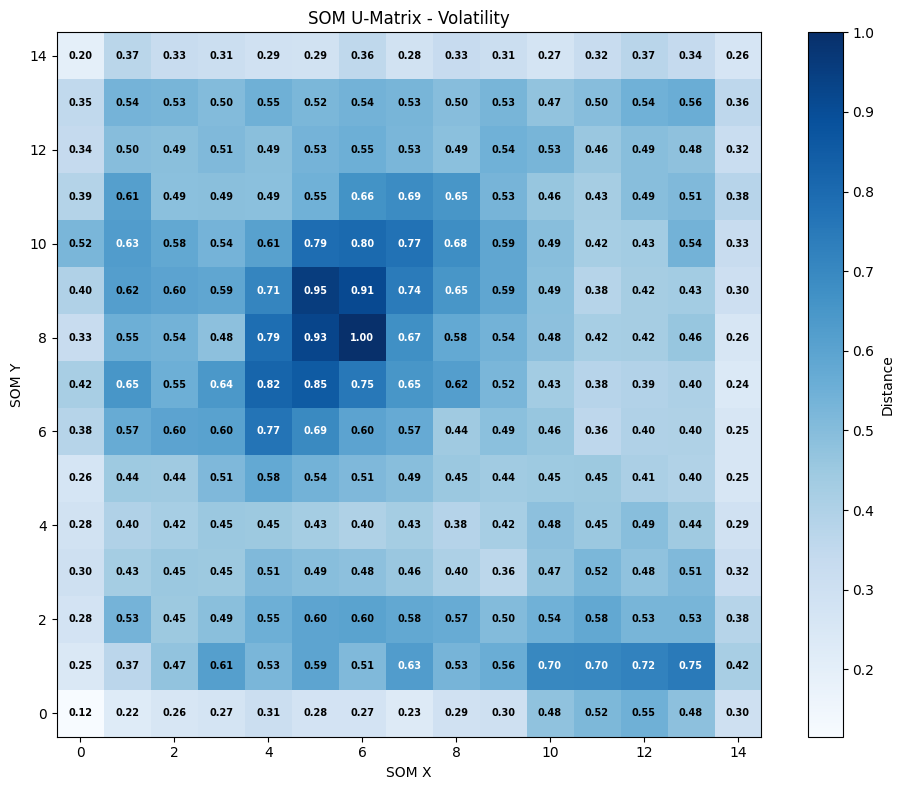


Διαστάσεις SOM weights: (15, 15, 23)
Αριθμός Component Maps: 23


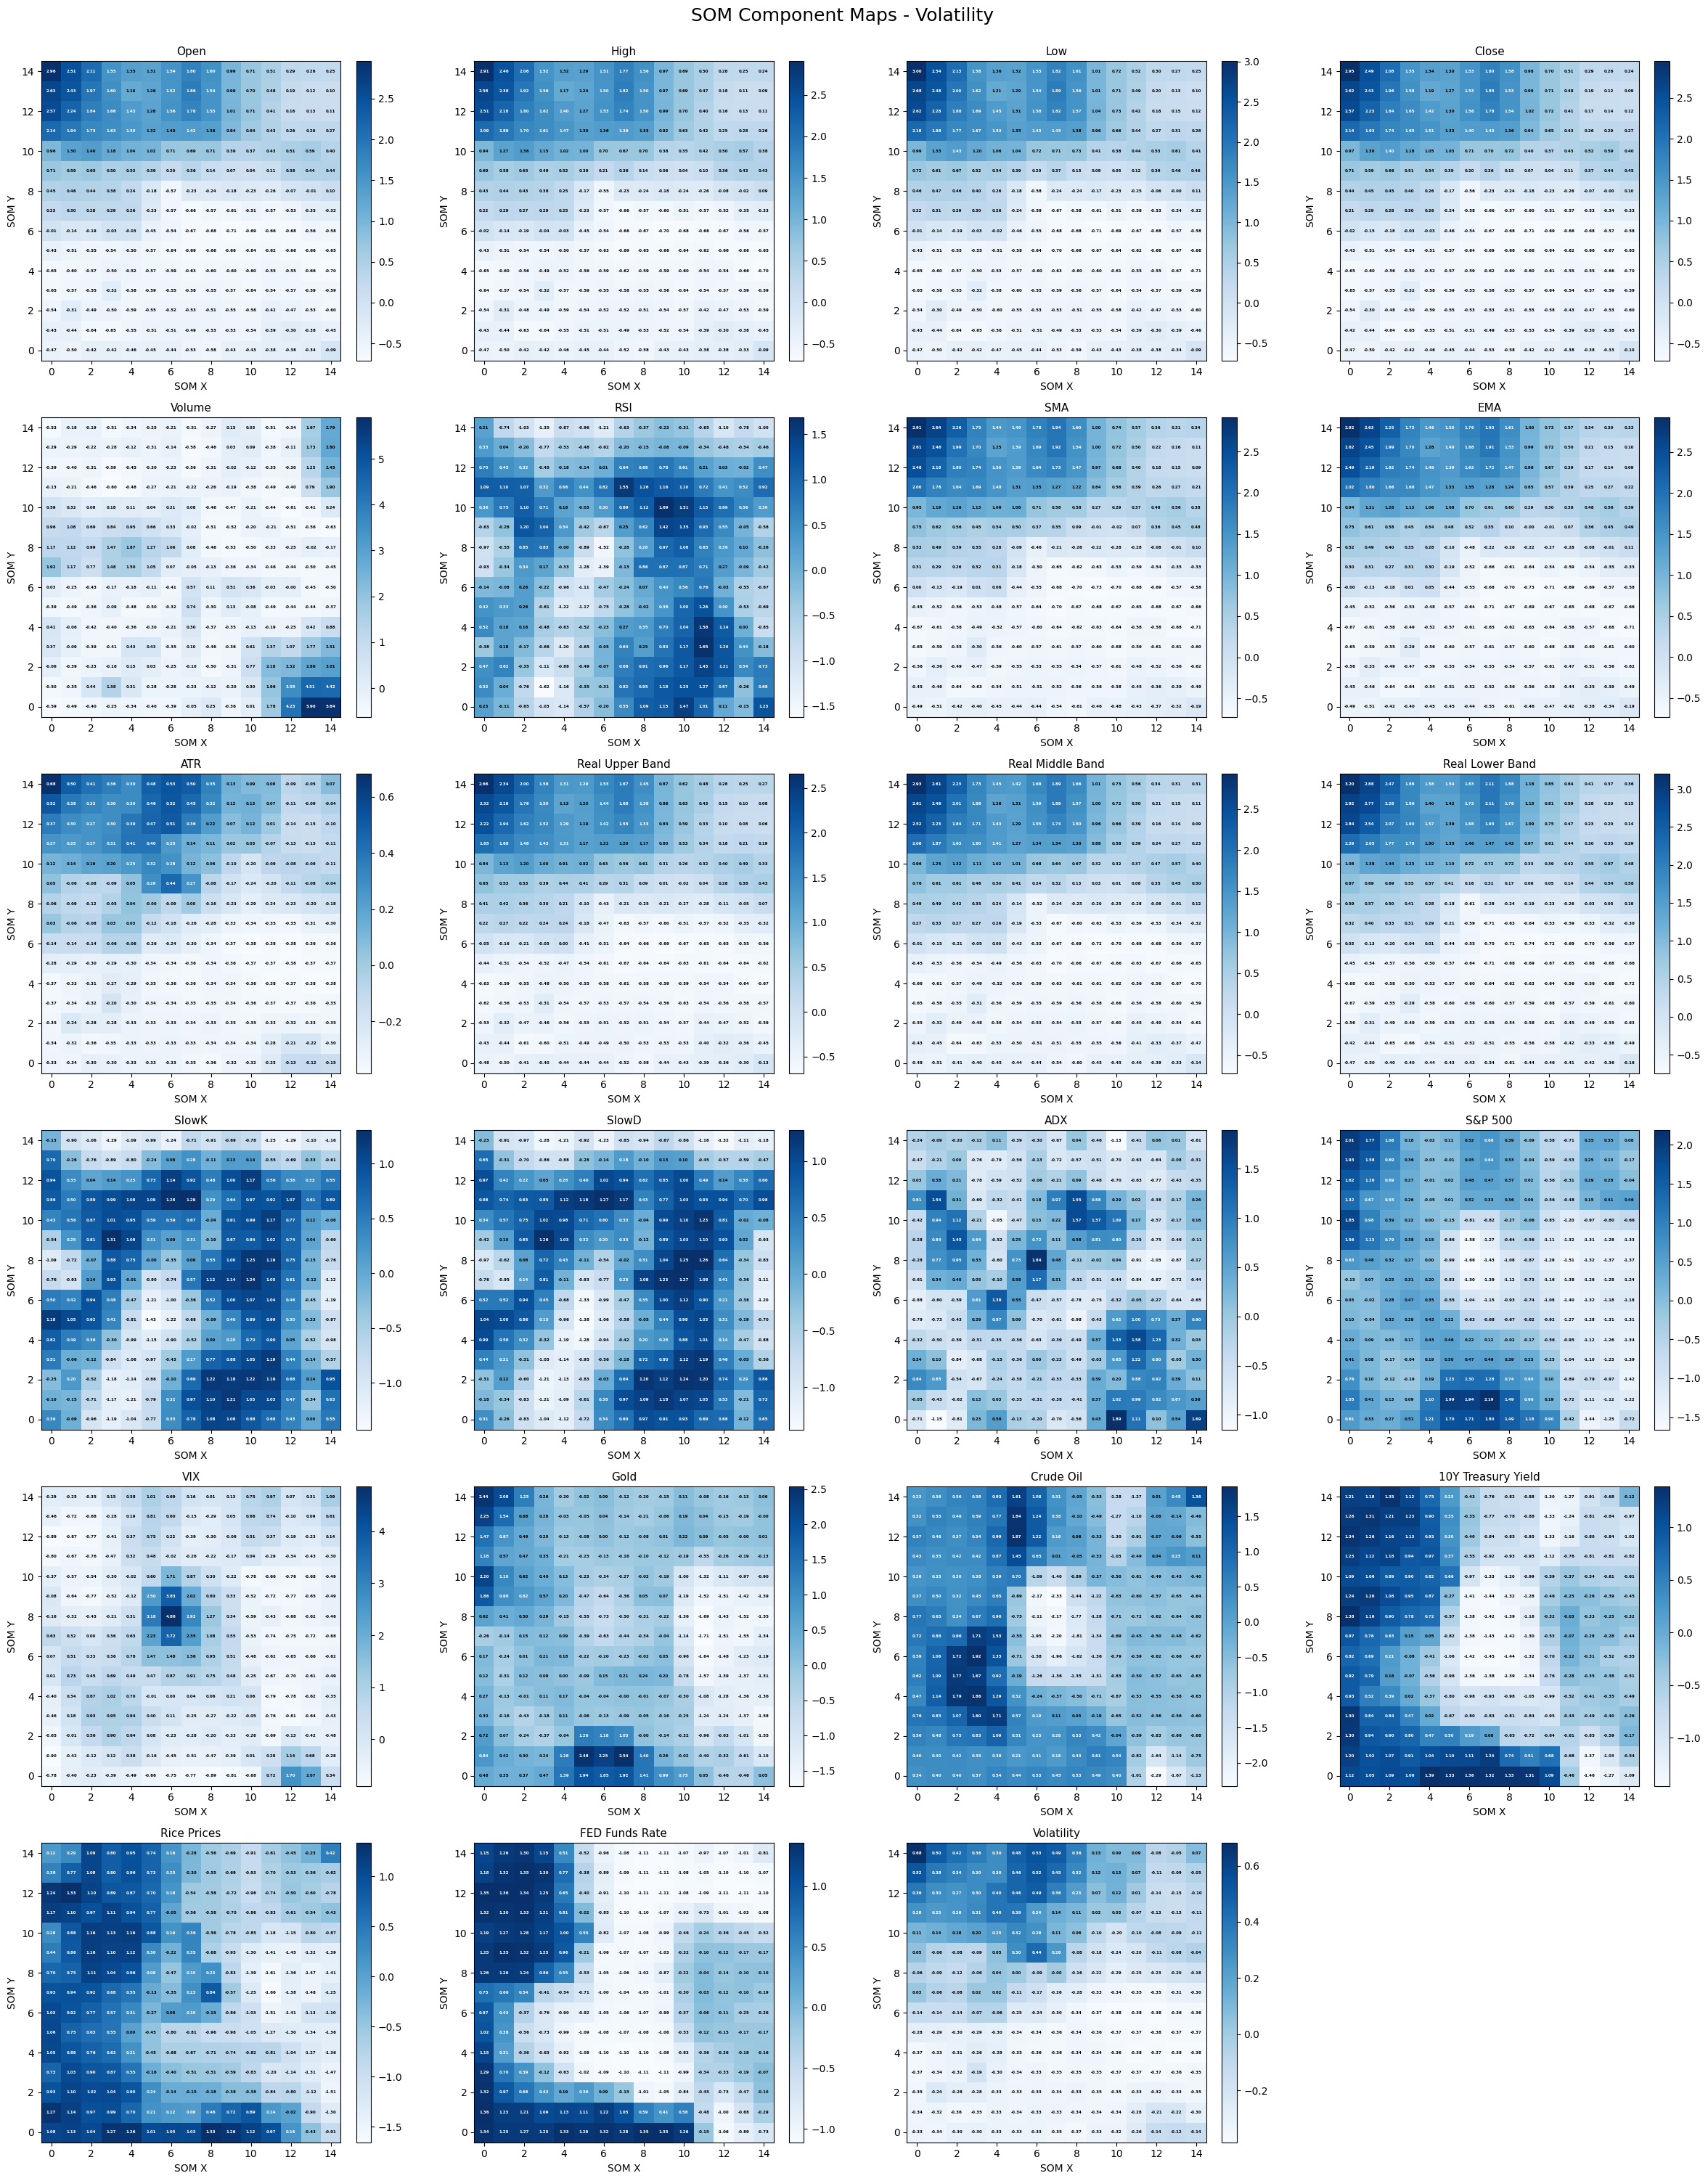

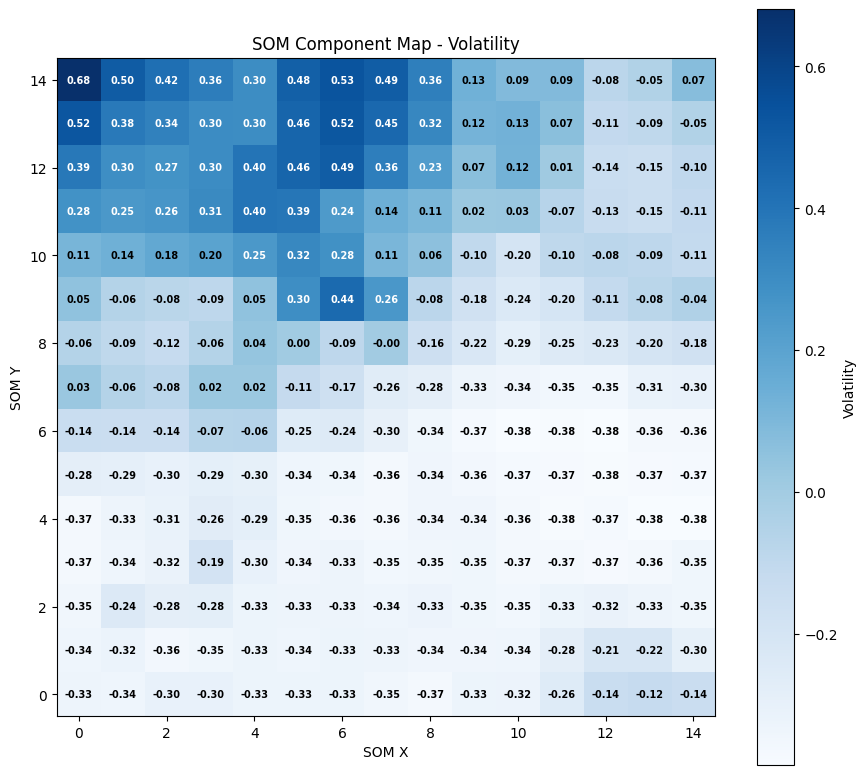


ΧΑΡΑΚΤΗΡΙΣΤΙΚΑ ΜΕ ΤΗ ΜΕΓΑΛΥΤΕΡΗ ΣΥΣΧΕΤΙΣΗ ΜΕ Volatility
               Feature  Correlation  Absolute_Correlation
0                  ATR     0.999906              0.999906
1                  SMA     0.951433              0.951433
2                  EMA     0.950063              0.950063
3      Real Upper Band     0.948869              0.948869
4     Real Middle Band     0.943299              0.943299
5                 High     0.939968              0.939968
6                Close     0.938924              0.938924
7                 Open     0.938756              0.938756
8                  Low     0.937687              0.937687
9      Real Lower Band     0.936536              0.936536
10         Rice Prices     0.283034              0.283034
11             S&P 500     0.256954              0.256954
12                Gold     0.251835              0.251835
13           Crude Oil     0.212370              0.212370
14  10Y Treasury Yield     0.152771              0.152771
15             

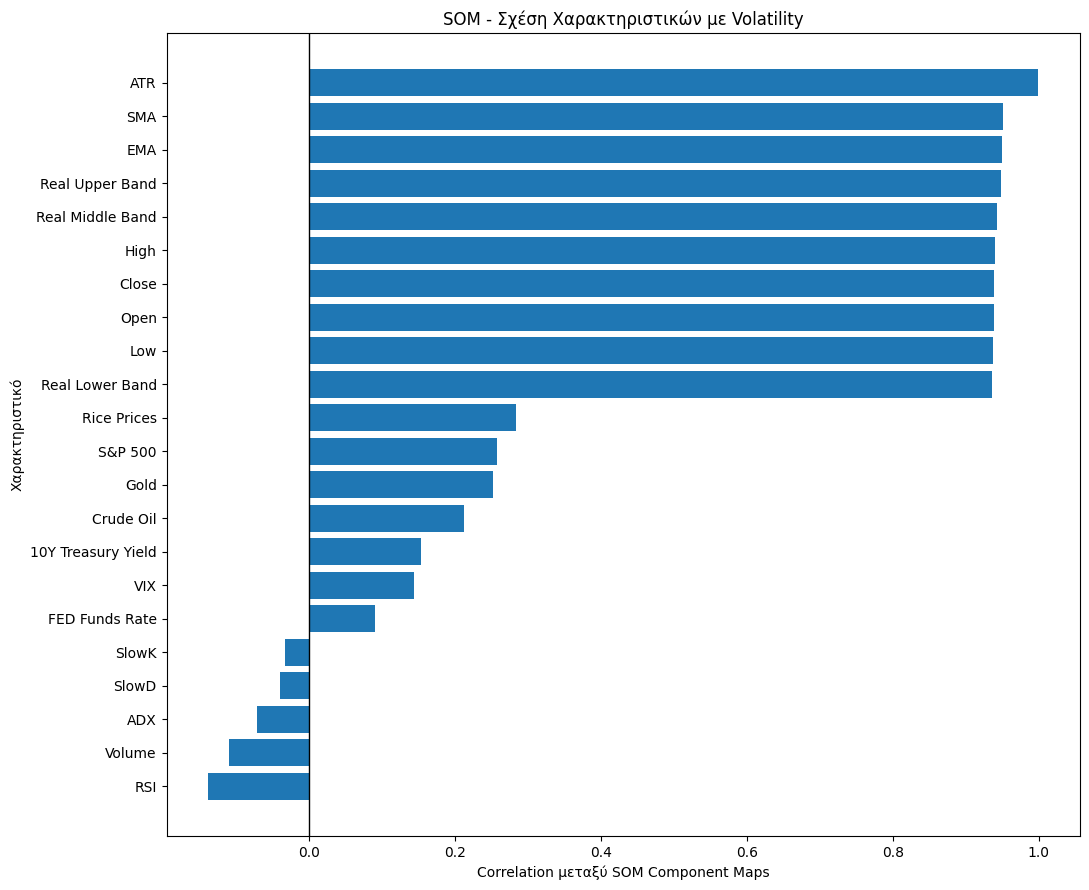


TOP 10 ΧΑΡΑΚΤΗΡΙΣΤΙΚΑ ΓΙΑ Volatility
            Feature  Correlation  Absolute_Correlation
0               ATR     0.999906              0.999906
1               SMA     0.951433              0.951433
2               EMA     0.950063              0.950063
3   Real Upper Band     0.948869              0.948869
4  Real Middle Band     0.943299              0.943299
5              High     0.939968              0.939968
6             Close     0.938924              0.938924
7              Open     0.938756              0.938756
8               Low     0.937687              0.937687
9   Real Lower Band     0.936536              0.936536


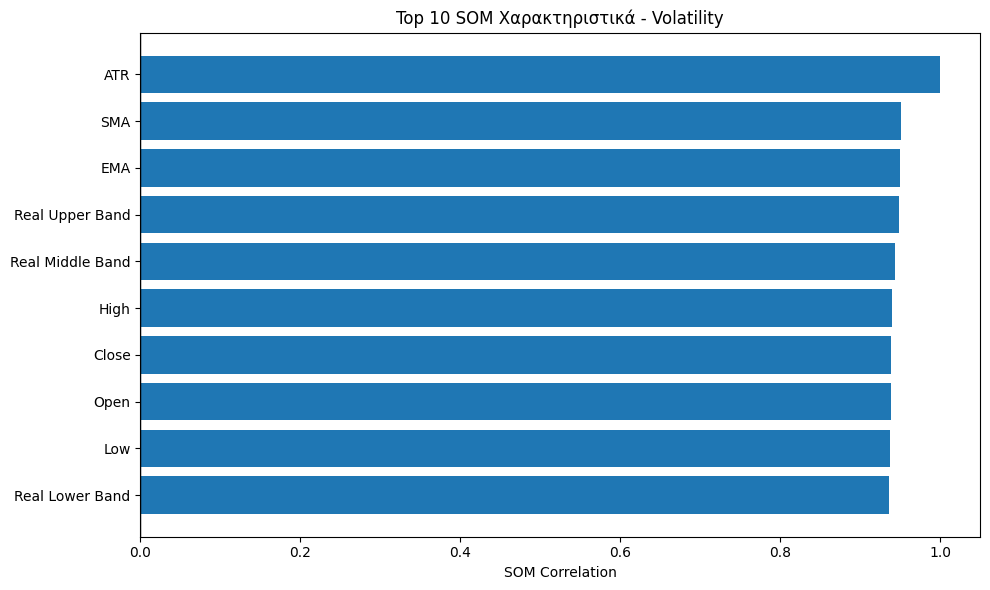


ΠΛΗΡΗΣ ΠΙΝΑΚΑΣ ΣΥΣΧΕΤΙΣΕΩΝ SOM COMPONENT MAPS
                    Open  High   Low  Close  Volume   RSI   SMA   EMA   ATR  \
Open                1.00  1.00  1.00   1.00   -0.17  0.01  1.00  1.00  0.94   
High                1.00  1.00  1.00   1.00   -0.17  0.01  1.00  1.00  0.94   
Low                 1.00  1.00  1.00   1.00   -0.18  0.01  1.00  1.00  0.94   
Close               1.00  1.00  1.00   1.00   -0.17  0.01  1.00  1.00  0.94   
Volume             -0.17 -0.17 -0.18  -0.17    1.00  0.03 -0.17 -0.18 -0.11   
RSI                 0.01  0.01  0.01   0.01    0.03  1.00 -0.04 -0.04 -0.14   
SMA                 1.00  1.00  1.00   1.00   -0.17 -0.04  1.00  1.00  0.95   
EMA                 1.00  1.00  1.00   1.00   -0.18 -0.04  1.00  1.00  0.95   
ATR                 0.94  0.94  0.94   0.94   -0.11 -0.14  0.95  0.95  1.00   
Real Upper Band     1.00  1.00  1.00   1.00   -0.17 -0.03  1.00  1.00  0.95   
Real Middle Band    1.00  1.00  1.00   1.00   -0.17 -0.02  1.00  1.00  0.94   
Real 

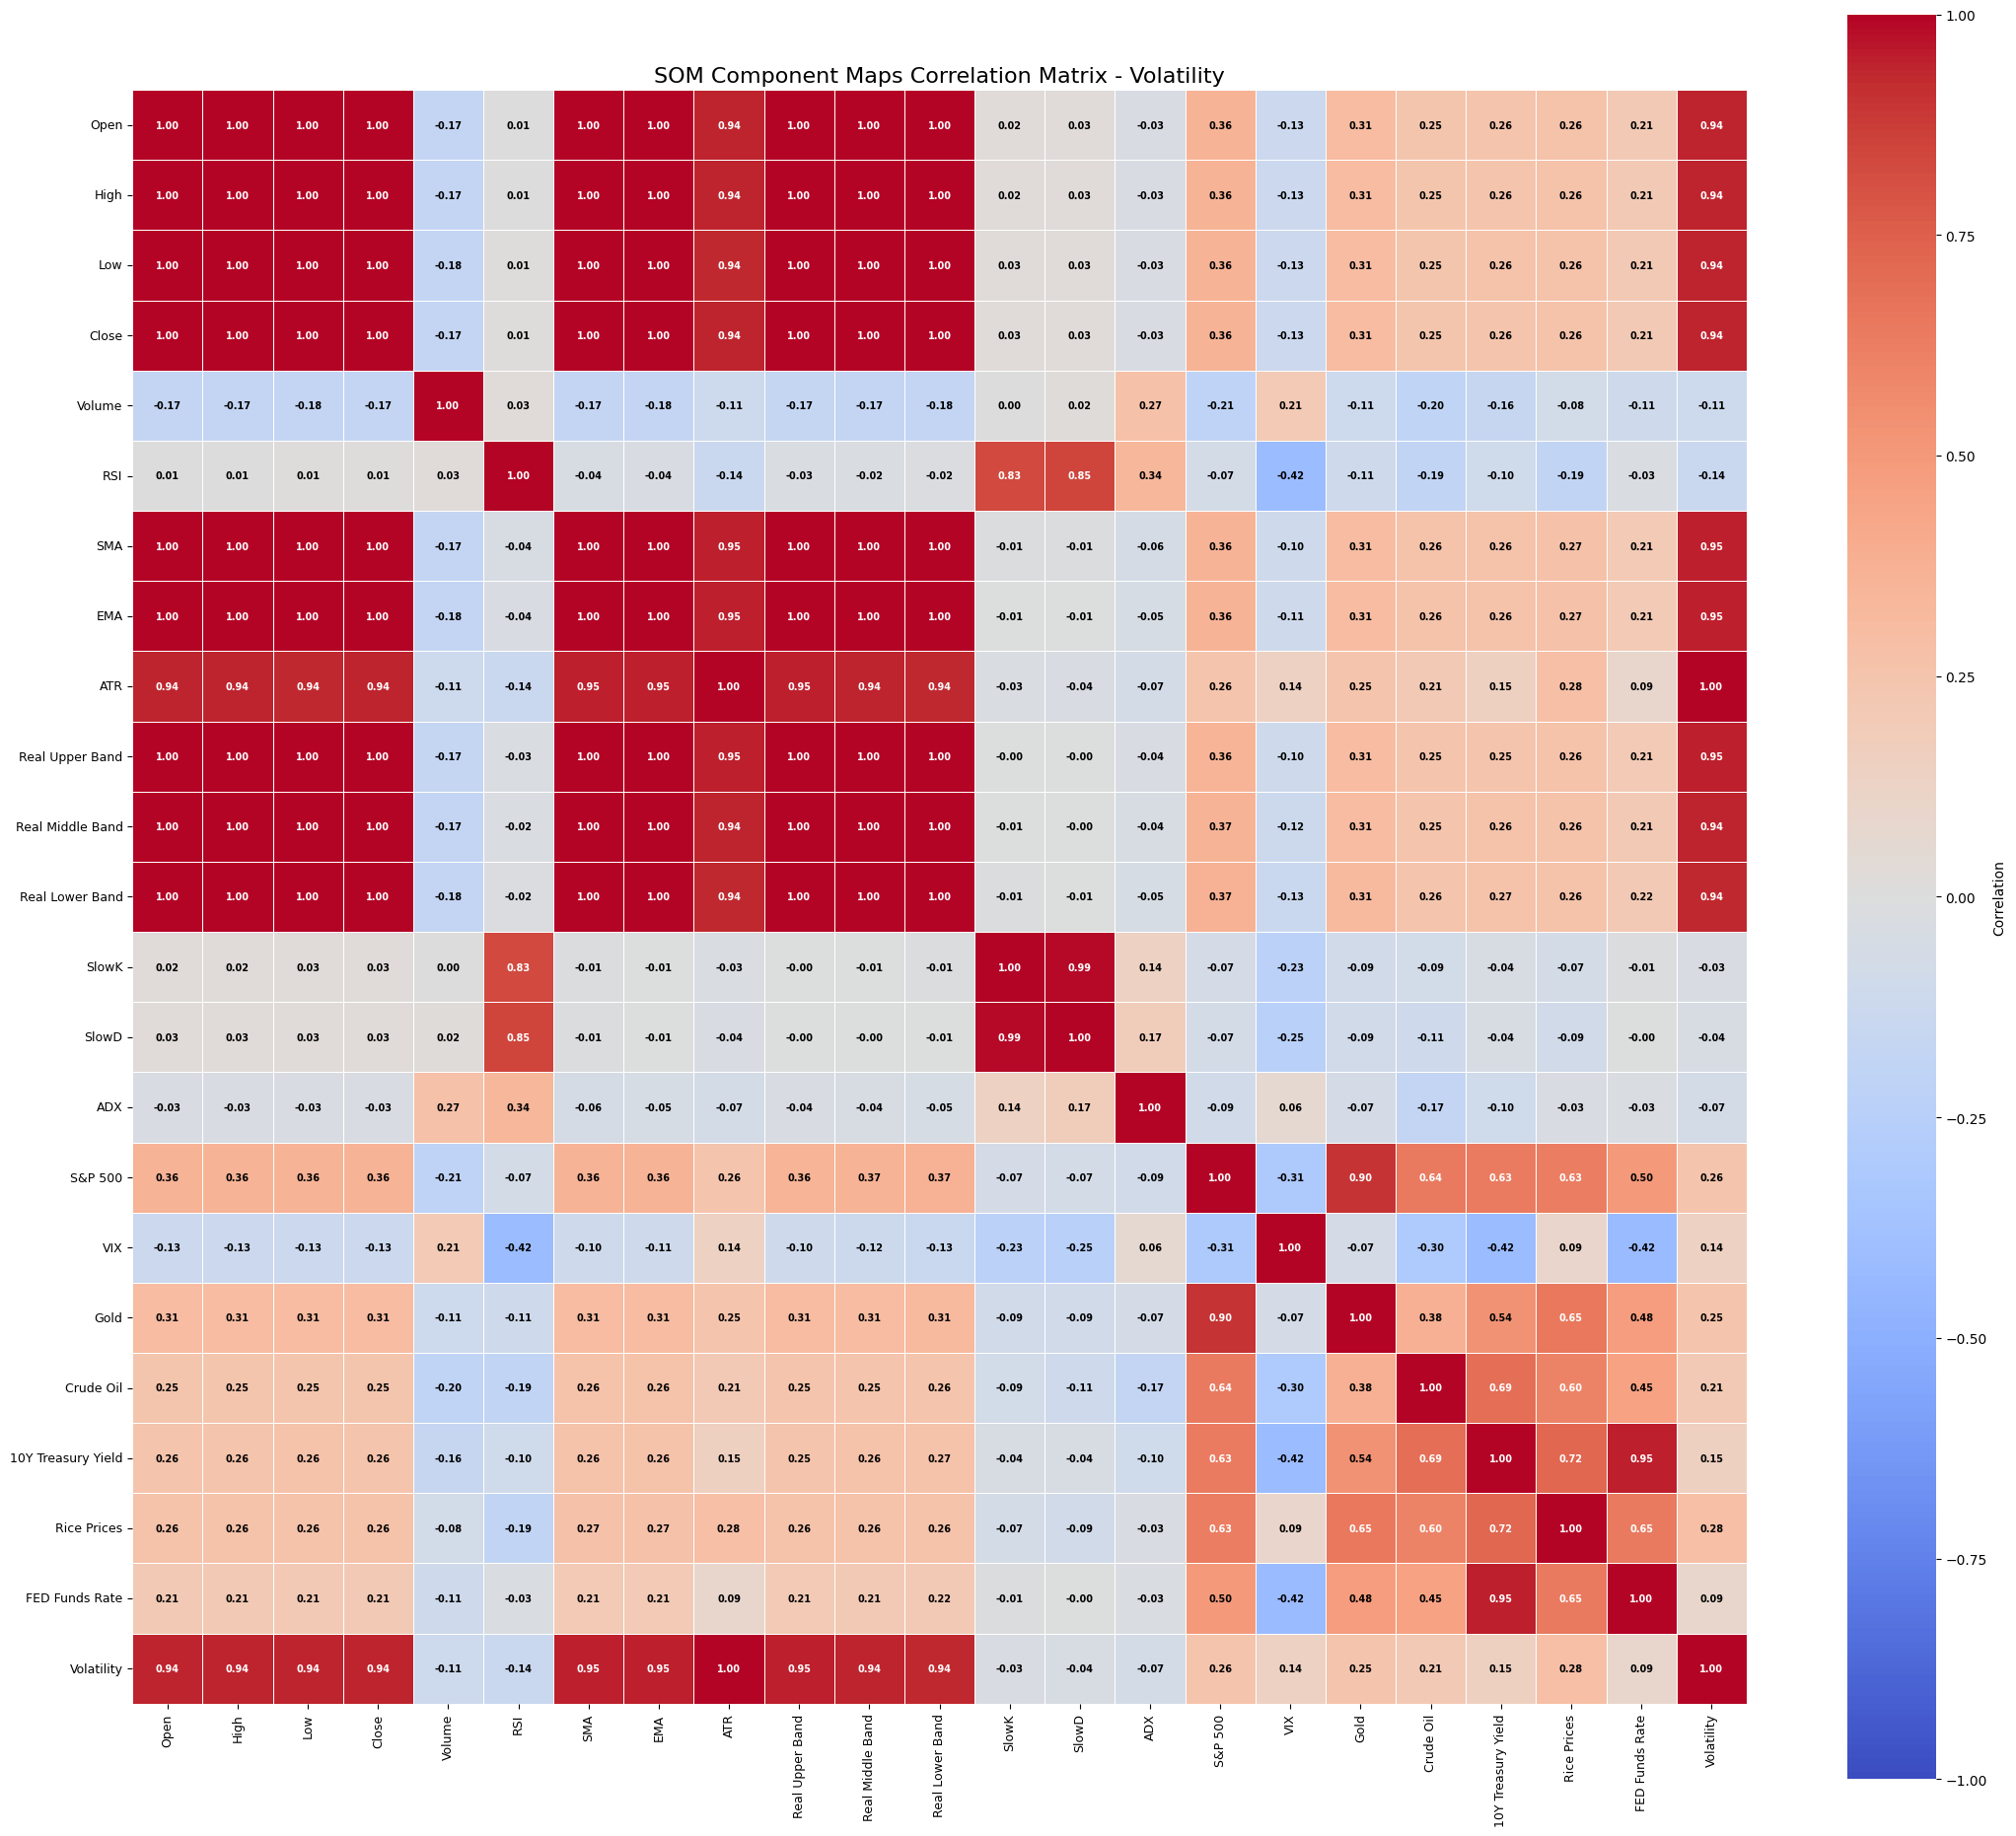


ΜΕΓΑΛΥΤΕΡΕΣ ΕΤΕΡΟΣΥΣΧΕΤΙΣΕΙΣ ΜΕΤΑΞΥ ΤΩΝ COMPONENT MAPS
          Variable_1        Variable_2  Correlation
0               Open              High     0.999989
1                Low             Close     0.999989
2               Open               Low     0.999988
3               High             Close     0.999986
4               Open             Close     0.999983
5               High               Low     0.999972
6                SMA               EMA     0.999946
7                ATR        Volatility     0.999906
8    Real Upper Band  Real Middle Band     0.999734
9   Real Middle Band   Real Lower Band     0.999673
10               EMA   Real Upper Band     0.999640
11               EMA  Real Middle Band     0.999555
12               SMA   Real Upper Band     0.999444
13               SMA  Real Middle Band     0.999324
14              High  Real Middle Band     0.999117
15              Open  Real Middle Band     0.999114
16             Close  Real Middle Band     0.998974
17      

In [15]:
# Εκτέλεση SOM για όλα τα targets
som_results = {}

for target in targets:
    som_model, correlations = run_som(
        dataset=dataset,
        features=features,
        target=target,
        som_x=15,
        som_y=15,
        iterations=10000,
        random_seed=42
    )

    som_results[target] = {
        "som": som_model,
        "correlations": correlations
    }

In [16]:
# Δημιουργία συγκεντρωτικού πίνακα
summary_tables = []

for target in targets:
    temp = som_results[target]["correlations"].copy()
    temp["Target"] = target

    summary_tables.append(temp)

all_correlations = pd.concat(summary_tables, ignore_index=True)

all_correlations = all_correlations[
    ["Target", "Feature", "Correlation", "Absolute_Correlation"]
]

print(all_correlations)


# Αποθήκευση συγκεντρωτικού πίνακα
all_correlations.to_excel(
    f"{output_path}ALL_SOM_CORRELATIONS.xlsx",
    index=False
)

        Target           Feature  Correlation  Absolute_Correlation
0   Next_Close             Close     0.999980              0.999980
1   Next_Close               Low     0.999968              0.999968
2   Next_Close              High     0.999962              0.999962
3   Next_Close              Open     0.999960              0.999960
4   Next_Close  Real Middle Band     0.998890              0.998890
..         ...               ...          ...                   ...
83  Volatility            Volume    -0.110578              0.110578
84  Volatility    FED Funds Rate     0.089784              0.089784
85  Volatility               ADX    -0.071482              0.071482
86  Volatility             SlowD    -0.040046              0.040046
87  Volatility             SlowK    -0.033659              0.033659

[88 rows x 4 columns]


In [17]:
# Επιλογή Top 10 χαρακτηριστικών ανά target
top10_all = (
    all_correlations
    .sort_values(
        ["Target", "Absolute_Correlation"],
        ascending=[True, False]
    )
    .groupby("Target")
    .head(10)
)

print(top10_all)


# Αποθήκευση Top 10 αποτελεσμάτων
top10_all.to_excel(
    f"{output_path}TOP10_SOM_ALL_TARGETS.xlsx",
    index=False
)

         Target             Feature  Correlation  Absolute_Correlation
0    Next_Close               Close     0.999980              0.999980
1    Next_Close                 Low     0.999968              0.999968
2    Next_Close                High     0.999962              0.999962
3    Next_Close                Open     0.999960              0.999960
4    Next_Close    Real Middle Band     0.998890              0.998890
5    Next_Close     Real Lower Band     0.998635              0.998635
6    Next_Close     Real Upper Band     0.998621              0.998621
7    Next_Close                 EMA     0.998120              0.998120
8    Next_Close                 SMA     0.997673              0.997673
9    Next_Close                 ATR     0.939528              0.939528
22  Next_Volume              Volume     0.989444              0.989444
23  Next_Volume                 VIX     0.247966              0.247966
24  Next_Volume           Crude Oil    -0.161306              0.161306
25  Ne

In [18]:
# Εμφάνιση Top 5 χαρακτηριστικών ανά target
for target in targets:
    temp = (
        all_correlations[
            all_correlations["Target"] == target
        ]
        .sort_values("Absolute_Correlation", ascending=False)
        .head(5)
    )

    print("\n" + "=" * 50)
    print("TOP 5 ΓΙΑ", target)
    print("=" * 50)

    print(temp[["Feature", "Correlation"]])


TOP 5 ΓΙΑ Next_Close
            Feature  Correlation
0             Close     0.999980
1               Low     0.999968
2              High     0.999962
3              Open     0.999960
4  Real Middle Band     0.998890

TOP 5 ΓΙΑ Next_Volume
               Feature  Correlation
22              Volume     0.989444
23                 VIX     0.247966
24           Crude Oil    -0.161306
25  10Y Treasury Yield    -0.158200
26                 ADX     0.157420

TOP 5 ΓΙΑ Trend
               Feature  Correlation
44           Crude Oil    -0.388817
45                 VIX     0.307400
46              Volume     0.259479
47             S&P 500    -0.210302
48  10Y Treasury Yield    -0.176399

TOP 5 ΓΙΑ Volatility
             Feature  Correlation
66               ATR     0.999906
67               SMA     0.951433
68               EMA     0.950063
69   Real Upper Band     0.948869
70  Real Middle Band     0.943299
